1 — Import Libraries and Configure Paths

In [1]:
# ============================================================
# CELL 1 - IMPORT LIBRARIES AND CONFIGURE PATHS
# Purpose:
# Initialize the bank routing investigation environment.
# ============================================================

from pathlib import Path
from collections import Counter
from itertools import combinations
from math import sqrt

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import chi2_contingency

# ------------------------------------------------------------
# Locate project root
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

assert (PROJECT_ROOT / "data").is_dir(), (
    "Project root directory not found."
)

# ------------------------------------------------------------
# Define dataset path
# ------------------------------------------------------------

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "cleaned"
    / "swift_payments_cleaned.csv"
)

assert DATA_PATH.is_file(), (
    f"Cleaned dataset not found: {DATA_PATH}"
)

# ------------------------------------------------------------
# Define dedicated output directories
# ------------------------------------------------------------

TABLE_DIR = PROJECT_ROOT / "outputs" / "tables" / "routing"
CHART_DIR = PROJECT_ROOT / "outputs" / "charts" / "routing"
RULE_DIR = PROJECT_ROOT / "outputs" / "rules"

for directory in [TABLE_DIR, CHART_DIR, RULE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Configure chunk processing
# ------------------------------------------------------------

CHUNK_SIZE = 25_000
MIN_GROUP_SIZE = 100
EXPECTED_RECORDS = 1_048_575

plt.rcParams["figure.figsize"] = (11, 6)
plt.rcParams["font.size"] = 11

print("=" * 65)
print("SWIFT DATATHON - BANK ROUTING INVESTIGATION")
print("=" * 65)

print("Dataset found:", DATA_PATH.exists())
print("Chunk size:", CHUNK_SIZE)
print("Table directory:", TABLE_DIR)
print("Chart directory:", CHART_DIR)
print("Rule directory:", RULE_DIR)

print("\nRouting analysis environment ready.")

SWIFT DATATHON - BANK ROUTING INVESTIGATION
Dataset found: True
Chunk size: 25000
Table directory: c:\Users\user\Documents\UMDAC_datathon\outputs\tables\routing
Chart directory: c:\Users\user\Documents\UMDAC_datathon\outputs\charts\routing
Rule directory: c:\Users\user\Documents\UMDAC_datathon\outputs\rules

Routing analysis environment ready.


2 — Validate Analytical Schema

In [2]:
# ============================================================
# CELL 2 - VALIDATE ANALYTICAL SCHEMA
# Purpose:
# Confirm all required routing analysis fields exist.
# ============================================================

REQUIRED_COLUMNS = [
    "TRANSACTION_TYPE_CODE_STD",
    "PARTICIPANT_COUNT_NUM",
    "FX_COUNT_NUM",
    "HAS_PATH_GAP",
    "CONTINUITY_QFLAG_STD",
    "BIC8_PATH",
    "ORDERING_BIC8",
    "BENEFICIARY_BIC8",
    "CURRENCY_CODE_STD",
    "PARTY_PAIR",
    "USD_AMOUNT_NUM"
]

available_columns = pd.read_csv(
    DATA_PATH,
    nrows=0
).columns.tolist()

missing_columns = [
    col for col in REQUIRED_COLUMNS
    if col not in available_columns
]

print("Available columns:", len(available_columns))
print("Required routing fields:", len(REQUIRED_COLUMNS))
print("Missing fields:", missing_columns)

assert not missing_columns, (
    "Required routing fields are missing."
)

print("\nRouting schema validation passed.")

Available columns: 46
Required routing fields: 11
Missing fields: []

Routing schema validation passed.


3 — Define Statistical Helper Functions

In [5]:
# ============================================================
# CELL 3 - DEFINE STATISTICAL HELPER FUNCTIONS
# Purpose:
# Provide reusable functions for routing rule reconstruction,
# statistical analysis, and evidence exports.
# ============================================================

import pandas as pd
import numpy as np

from scipy.stats import chi2_contingency


# ------------------------------------------------------------
# 1. Safe division
# ------------------------------------------------------------

def safe_divide(numerator, denominator):

    if denominator == 0:
        return np.nan

    return numerator / denominator


# ------------------------------------------------------------
# 2. Calculate percentage
# ------------------------------------------------------------

def safe_percentage(numerator, denominator):

    return safe_divide(numerator, denominator) * 100


# ------------------------------------------------------------
# 3. Calculate Wilson confidence interval
# ------------------------------------------------------------

def wilson_interval(successes, total, z=1.96):

    if total <= 0:
        return np.nan, np.nan

    p = successes / total
    z_squared = z ** 2

    denominator = 1 + z_squared / total

    center = (
        p + z_squared / (2 * total)
    ) / denominator

    margin = (
        z / denominator
        * np.sqrt(
            p * (1 - p) / total
            + z_squared / (4 * total ** 2)
        )
    )

    lower_bound = max(0, center - margin)
    upper_bound = min(1, center + margin)

    return lower_bound, upper_bound


# ------------------------------------------------------------
# 4. Calculate Cramer's V association strength
# ------------------------------------------------------------

def cramers_v(contingency_table):

    table = np.asarray(
        contingency_table,
        dtype=float
    )

    # Remove empty rows and columns
    table = table[
        table.sum(axis=1) > 0
    ]

    table = table[
        :,
        table.sum(axis=0) > 0
    ]

    # Association requires at least two categories
    if min(table.shape) < 2:
        return np.nan, np.nan

    chi2, p_value, _, _ = chi2_contingency(
        table,
        correction=False
    )

    total = table.sum()

    effect_size = np.sqrt(
        chi2 / (
            total * (min(table.shape) - 1)
        )
    )

    return effect_size, p_value


# ------------------------------------------------------------
# 5. Export a DataFrame to CSV
# ------------------------------------------------------------

def export_table(df, filename):

    output_path = TABLE_DIR / filename

    df.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig"
    )

    print(f"Exported: {filename}")


# ------------------------------------------------------------
# 6. Export a Matplotlib chart
# ------------------------------------------------------------

def export_chart(filename):

    output_path = CHART_DIR / filename

    plt.savefig(
        output_path,
        dpi=200,
        bbox_inches="tight"
    )

    print(f"Chart exported: {filename}")


# ------------------------------------------------------------
# 7. Convert Counter results into a DataFrame
# ------------------------------------------------------------

def counter_to_dataframe(counter, columns):

    records = []

    for key, count in counter.items():

        # Convert a single grouping value into a tuple
        if not isinstance(key, tuple):
            key = (key,)

        # Verify the expected number of grouping fields
        if len(key) != len(columns):
            raise ValueError(
                f"Expected {len(columns)} grouping values, "
                f"but received {len(key)}: {key}"
            )

        # Preserve the complete grouping values
        records.append(
            list(key) + [count]
        )

    result = pd.DataFrame(
        records,
        columns=columns + ["TRANSACTION_COUNT"]
    )

    return result


# ------------------------------------------------------------
# 8. Verify the corrected Counter conversion
# ------------------------------------------------------------

test_counter_single = Counter({
    "DIRECT": 100,
    "INDIRECT": 50,
    "COVERED": 20
})

test_single = counter_to_dataframe(
    test_counter_single,
    ["ROUTING_TYPE"]
)

assert test_single.shape == (3, 2)

assert test_single["TRANSACTION_COUNT"].sum() == 170


test_counter_multiple = Counter({
    ("DIRECT", 2): 100,
    ("INDIRECT", 3): 50,
    ("COVERED", 4): 20
})

test_multiple = counter_to_dataframe(
    test_counter_multiple,
    ["ROUTING_TYPE", "PARTICIPANT_COUNT"]
)

assert test_multiple.shape == (3, 3)

assert test_multiple["TRANSACTION_COUNT"].sum() == 170


# ------------------------------------------------------------
# 9. Display setup confirmation
# ------------------------------------------------------------

print("=" * 65)
print("STATISTICAL HELPER FUNCTIONS")
print("=" * 65)

print("Safe division: Ready")
print("Percentage calculation: Ready")
print("Wilson confidence interval: Ready")
print("Cramer's V association test: Ready")
print("CSV export: Ready")
print("Chart export: Ready")
print("Counter conversion: Ready")

print("\nSingle-key Counter test: PASSED")
print("Multi-key Counter test: PASSED")

print("\nAll statistical helper functions initialized.")

STATISTICAL HELPER FUNCTIONS
Safe division: Ready
Percentage calculation: Ready
Wilson confidence interval: Ready
Cramer's V association test: Ready
CSV export: Ready
Chart export: Ready
Counter conversion: Ready

Single-key Counter test: PASSED
Multi-key Counter test: PASSED

All statistical helper functions initialized.


4 — Aggregate Routing Evidence

In [6]:
# ============================================================
# CELL 4 - AGGREGATE ROUTING EVIDENCE
# Purpose:
# Build multivariable routing evidence tables from the
# complete cleaned dataset using chunk-based processing.
#
# Data protection:
# - No source rows are deleted.
# - No original values are modified.
# - All operations are read-only aggregations.
# ============================================================

from collections import Counter

import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 1. Define required columns
# ------------------------------------------------------------

ROUTING_COLUMNS = [
    "TRANSACTION_TYPE_CODE_STD",
    "PARTICIPANT_COUNT_NUM",
    "FX_COUNT_NUM",
    "HAS_PATH_GAP",
    "CONTINUITY_QFLAG_STD",
    "CURRENCY_CODE_STD",
    "PARTY_PAIR",
    "ORDERING_BIC8",
    "BENEFICIARY_BIC8"
]


# ------------------------------------------------------------
# 2. Initialize aggregation counters
# ------------------------------------------------------------

routing_counter = Counter()

routing_participant_counter = Counter()

routing_fx_counter = Counter()

participant_fx_counter = Counter()

routing_participant_fx_counter = Counter()

routing_gap_counter = Counter()

routing_participant_gap_counter = Counter()

routing_fx_gap_counter = Counter()

routing_currency_party_counter = Counter()

bic_pair_route_counter = Counter()


# ------------------------------------------------------------
# 3. Initialize validation counters
# ------------------------------------------------------------

total_records = 0
invalid_numeric_rows = 0
chunk_count = 0

missing_routing_values = 0
missing_currency_values = 0


# ------------------------------------------------------------
# 4. Define aggregation combinations
# ------------------------------------------------------------

GROUP_DEFINITIONS = [
    (
        ["ROUTING_TYPE"],
        routing_counter
    ),
    (
        ["ROUTING_TYPE", "PARTICIPANT_COUNT"],
        routing_participant_counter
    ),
    (
        ["ROUTING_TYPE", "FX_COUNT"],
        routing_fx_counter
    ),
    (
        ["PARTICIPANT_COUNT", "FX_COUNT"],
        participant_fx_counter
    ),
    (
        [
            "ROUTING_TYPE",
            "PARTICIPANT_COUNT",
            "FX_COUNT"
        ],
        routing_participant_fx_counter
    ),
    (
        ["ROUTING_TYPE", "HAS_PATH_GAP"],
        routing_gap_counter
    ),
    (
        [
            "ROUTING_TYPE",
            "PARTICIPANT_COUNT",
            "HAS_PATH_GAP"
        ],
        routing_participant_gap_counter
    ),
    (
        [
            "ROUTING_TYPE",
            "FX_COUNT",
            "HAS_PATH_GAP"
        ],
        routing_fx_gap_counter
    ),
    (
        [
            "ROUTING_TYPE",
            "CURRENCY",
            "PARTY_PAIR"
        ],
        routing_currency_party_counter
    ),
    (
        [
            "ORDERING_BIC8",
            "BENEFICIARY_BIC8",
            "ROUTING_TYPE"
        ],
        bic_pair_route_counter
    )
]


# ------------------------------------------------------------
# 5. Create chunk reader
# ------------------------------------------------------------

reader = pd.read_csv(
    DATA_PATH,
    usecols=ROUTING_COLUMNS,
    dtype=str,
    keep_default_na=False,
    na_filter=False,
    chunksize=CHUNK_SIZE
)


# ------------------------------------------------------------
# 6. Process the complete dataset
# ------------------------------------------------------------

for chunk_number, chunk in enumerate(reader, start=1):

    chunk_count += 1

    total_records += len(chunk)

    # --------------------------------------------------------
    # 6.1 Create standardized analysis values
    # --------------------------------------------------------

    chunk["ROUTING_TYPE"] = (
        chunk["TRANSACTION_TYPE_CODE_STD"]
        .str.strip()
        .str.upper()
    )

    chunk["CURRENCY"] = (
        chunk["CURRENCY_CODE_STD"]
        .str.strip()
        .str.upper()
    )

    chunk["PARTY_PAIR"] = (
        chunk["PARTY_PAIR"]
        .str.strip()
        .str.upper()
    )

    chunk["HAS_PATH_GAP"] = (
        chunk["HAS_PATH_GAP"]
        .str.strip()
        .str.upper()
    )

    # --------------------------------------------------------
    # 6.2 Convert numeric analysis values
    # --------------------------------------------------------

    chunk["PARTICIPANT_COUNT"] = pd.to_numeric(
        chunk["PARTICIPANT_COUNT_NUM"],
        errors="coerce"
    )

    chunk["FX_COUNT"] = pd.to_numeric(
        chunk["FX_COUNT_NUM"],
        errors="coerce"
    )

    invalid_numeric_rows += int(
        chunk[
            ["PARTICIPANT_COUNT", "FX_COUNT"]
        ].isna().any(axis=1).sum()
    )

    # Use -1 only as an analysis-group placeholder.
    # The source dataset is not modified.
    chunk["PARTICIPANT_COUNT"] = (
        chunk["PARTICIPANT_COUNT"]
        .fillna(-1)
        .astype("int64")
    )

    chunk["FX_COUNT"] = (
        chunk["FX_COUNT"]
        .fillna(-1)
        .astype("int64")
    )

    # --------------------------------------------------------
    # 6.3 Handle categorical grouping values
    # --------------------------------------------------------

    missing_routing_values += int(
        chunk["ROUTING_TYPE"].eq("").sum()
    )

    missing_currency_values += int(
        chunk["CURRENCY"].eq("").sum()
    )

    chunk["ROUTING_TYPE"] = (
        chunk["ROUTING_TYPE"].replace(
            "",
            "MISSING"
        )
    )

    chunk["CURRENCY"] = (
        chunk["CURRENCY"].replace(
            "",
            "MISSING"
        )
    )

    chunk["PARTY_PAIR"] = (
        chunk["PARTY_PAIR"].replace(
            "",
            "UNKNOWN"
        )
    )

    chunk["HAS_PATH_GAP"] = (
        chunk["HAS_PATH_GAP"].replace(
            "",
            "UNKNOWN"
        )
    )

    # --------------------------------------------------------
    # 6.4 Normalize BIC identifiers for grouping only
    # --------------------------------------------------------

    chunk["ORDERING_BIC8"] = (
        chunk["ORDERING_BIC8"]
        .str.strip()
    )

    chunk["BENEFICIARY_BIC8"] = (
        chunk["BENEFICIARY_BIC8"]
        .str.strip()
    )

    # --------------------------------------------------------
    # 6.5 Aggregate multivariable combinations
    # --------------------------------------------------------

    for group_columns, counter in GROUP_DEFINITIONS:

        frequencies = (
            chunk.groupby(
                group_columns,
                dropna=False
            )
            .size()
        )

        counter.update(
            frequencies.to_dict()
        )

    # --------------------------------------------------------
    # 6.6 Display progress every 10 chunks
    # --------------------------------------------------------

    if chunk_number % 10 == 0:

        print(
            f"Chunk {chunk_number}: "
            f"{total_records:,} records aggregated"
        )


# ------------------------------------------------------------
# 7. Convert Counter results to DataFrames
# ------------------------------------------------------------

routing_table = counter_to_dataframe(
    routing_counter,
    ["ROUTING_TYPE"]
)

routing_participant_table = counter_to_dataframe(
    routing_participant_counter,
    [
        "ROUTING_TYPE",
        "PARTICIPANT_COUNT"
    ]
)

routing_fx_table = counter_to_dataframe(
    routing_fx_counter,
    [
        "ROUTING_TYPE",
        "FX_COUNT"
    ]
)

participant_fx_table = counter_to_dataframe(
    participant_fx_counter,
    [
        "PARTICIPANT_COUNT",
        "FX_COUNT"
    ]
)

routing_participant_fx_table = counter_to_dataframe(
    routing_participant_fx_counter,
    [
        "ROUTING_TYPE",
        "PARTICIPANT_COUNT",
        "FX_COUNT"
    ]
)

routing_gap_table = counter_to_dataframe(
    routing_gap_counter,
    [
        "ROUTING_TYPE",
        "HAS_PATH_GAP"
    ]
)

routing_participant_gap_table = counter_to_dataframe(
    routing_participant_gap_counter,
    [
        "ROUTING_TYPE",
        "PARTICIPANT_COUNT",
        "HAS_PATH_GAP"
    ]
)

routing_fx_gap_table = counter_to_dataframe(
    routing_fx_gap_counter,
    [
        "ROUTING_TYPE",
        "FX_COUNT",
        "HAS_PATH_GAP"
    ]
)

routing_currency_party_table = counter_to_dataframe(
    routing_currency_party_counter,
    [
        "ROUTING_TYPE",
        "CURRENCY",
        "PARTY_PAIR"
    ]
)

bic_pair_route_table = counter_to_dataframe(
    bic_pair_route_counter,
    [
        "ORDERING_BIC8",
        "BENEFICIARY_BIC8",
        "ROUTING_TYPE"
    ]
)


# ------------------------------------------------------------
# 8. Organize evidence tables
# ------------------------------------------------------------

evidence_tables = {
    "routing_distribution.csv":
        routing_table,

    "routing_participant.csv":
        routing_participant_table,

    "routing_fx.csv":
        routing_fx_table,

    "participant_fx.csv":
        participant_fx_table,

    "routing_participant_fx.csv":
        routing_participant_fx_table,

    "routing_gap.csv":
        routing_gap_table,

    "routing_participant_gap.csv":
        routing_participant_gap_table,

    "routing_fx_gap.csv":
        routing_fx_gap_table,

    "routing_currency_party.csv":
        routing_currency_party_table,

    "bic_pair_route.csv":
        bic_pair_route_table
}


# ------------------------------------------------------------
# 9. Validate all evidence table totals
# ------------------------------------------------------------

validation_results = []

for filename, table in evidence_tables.items():

    actual_records = int(
        table["TRANSACTION_COUNT"].sum()
    )

    validation_results.append({
        "TABLE": filename,
        "EXPECTED_RECORDS": EXPECTED_RECORDS,
        "ACTUAL_RECORDS": actual_records,
        "MATCH": actual_records == EXPECTED_RECORDS
    })


validation_df = pd.DataFrame(validation_results)

assert total_records == EXPECTED_RECORDS, (
    "Dataset record count does not match the expected value."
)

assert validation_df["MATCH"].all(), (
    "One or more evidence tables failed validation."
)


# ------------------------------------------------------------
# 10. Export validated evidence tables
# ------------------------------------------------------------

for filename, table in evidence_tables.items():

    export_table(
        table,
        filename
    )


# ------------------------------------------------------------
# 11. Display final results
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("BANK ROUTING AGGREGATION SUMMARY")
print("=" * 65)

print("Chunks processed:", chunk_count)

print(
    "Total transactions:",
    f"{total_records:,}"
)

print(
    "Invalid numeric rows:",
    invalid_numeric_rows
)

print(
    "Missing routing values:",
    missing_routing_values
)

print(
    "Missing currency values:",
    missing_currency_values
)

print(
    "Evidence tables exported:",
    len(evidence_tables)
)

print("\nRouting Type Distribution:")

display(
    routing_table.sort_values(
        "TRANSACTION_COUNT",
        ascending=False
    )
)

print("\nEvidence Table Validation:")

display(validation_df)

print("\nAll routing aggregation checks passed.")
print("Original dataset remains unchanged.")

Chunk 10: 250,000 records aggregated
Chunk 20: 500,000 records aggregated
Chunk 30: 750,000 records aggregated
Chunk 40: 1,000,000 records aggregated
Exported: routing_distribution.csv
Exported: routing_participant.csv
Exported: routing_fx.csv
Exported: participant_fx.csv
Exported: routing_participant_fx.csv
Exported: routing_gap.csv
Exported: routing_participant_gap.csv
Exported: routing_fx_gap.csv
Exported: routing_currency_party.csv
Exported: bic_pair_route.csv

BANK ROUTING AGGREGATION SUMMARY
Chunks processed: 42
Total transactions: 1,048,575
Invalid numeric rows: 0
Missing routing values: 0
Missing currency values: 0
Evidence tables exported: 10

Routing Type Distribution:


,ROUTING_TYPE,TRANSACTION_COUNT
1,DIRECT,662245
2,INDIRECT,342752
0,COVERED,43578



Evidence Table Validation:


,TABLE,EXPECTED_RECORDS,ACTUAL_RECORDS,MATCH
0,routing_distribution.csv,1048575,1048575,True
1,routing_participant.csv,1048575,1048575,True
2,routing_fx.csv,1048575,1048575,True
3,participant_fx.csv,1048575,1048575,True
4,routing_participant_fx.csv,1048575,1048575,True
5,routing_gap.csv,1048575,1048575,True
6,routing_participant_gap.csv,1048575,1048575,True
7,routing_fx_gap.csv,1048575,1048575,True
8,routing_currency_party.csv,1048575,1048575,True
9,bic_pair_route.csv,1048575,1048575,True



All routing aggregation checks passed.
Original dataset remains unchanged.


5 — Validate the Routing Structure Rules

In [7]:
# ============================================================
# CELL 5 - VALIDATE ROUTING STRUCTURE RULES
# Purpose:
# Test observed deterministic relationships among routing
# type, participant count, and FX conversions.
# ============================================================

# ------------------------------------------------------------
# H01 - Direct routing and participant count
# ------------------------------------------------------------

direct_records = routing_participant_table.loc[
    routing_participant_table["ROUTING_TYPE"] == "DIRECT",
    "TRANSACTION_COUNT"
].sum()

direct_with_two = routing_participant_table.loc[
    (
        routing_participant_table["ROUTING_TYPE"] == "DIRECT"
    )
    &
    (
        routing_participant_table["PARTICIPANT_COUNT"] == 2
    ),
    "TRANSACTION_COUNT"
].sum()

direct_exceptions = direct_records - direct_with_two


# ------------------------------------------------------------
# H02 - Non-direct routing when FX >= 2
# ------------------------------------------------------------

fx_two_or_more = routing_fx_table.loc[
    routing_fx_table["FX_COUNT"] >= 2,
    "TRANSACTION_COUNT"
].sum()

direct_fx_two_or_more = routing_fx_table.loc[
    (
        routing_fx_table["ROUTING_TYPE"] == "DIRECT"
    )
    &
    (
        routing_fx_table["FX_COUNT"] >= 2
    ),
    "TRANSACTION_COUNT"
].sum()

fx_rule_support = (
    fx_two_or_more - direct_fx_two_or_more
)


# ------------------------------------------------------------
# H03 - Participant count = 2 implies Direct
# ------------------------------------------------------------

two_participant_records = routing_participant_table.loc[
    routing_participant_table["PARTICIPANT_COUNT"] == 2,
    "TRANSACTION_COUNT"
].sum()

two_participant_direct = routing_participant_table.loc[
    (
        routing_participant_table["PARTICIPANT_COUNT"] == 2
    )
    &
    (
        routing_participant_table["ROUTING_TYPE"] == "DIRECT"
    ),
    "TRANSACTION_COUNT"
].sum()


# ------------------------------------------------------------
# Create hypothesis evidence table
# ------------------------------------------------------------

structural_rules = pd.DataFrame([
    {
        "RULE_ID": "BR01",
        "HYPOTHESIS": "Direct implies participant count equals 2",
        "SUPPORT": direct_with_two,
        "SCOPE": direct_records,
        "EXCEPTIONS": direct_exceptions
    },
    {
        "RULE_ID": "BR02",
        "HYPOTHESIS": "FX count >= 2 implies non-direct routing",
        "SUPPORT": fx_rule_support,
        "SCOPE": fx_two_or_more,
        "EXCEPTIONS": direct_fx_two_or_more
    },
    {
        "RULE_ID": "BR03",
        "HYPOTHESIS": "Participant count equals 2 implies Direct",
        "SUPPORT": two_participant_direct,
        "SCOPE": two_participant_records,
        "EXCEPTIONS": (
            two_participant_records - two_participant_direct
        )
    }
])

structural_rules["SUPPORT_PERCENT"] = (
    structural_rules["SUPPORT"]
    / structural_rules["SCOPE"].replace(0, np.nan)
    * 100
)

export_table(
    structural_rules,
    "structural_rule_evidence.csv"
)

display(structural_rules)

Exported: structural_rule_evidence.csv


,RULE_ID,HYPOTHESIS,SUPPORT,SCOPE,EXCEPTIONS,SUPPORT_PERCENT
0,BR01,Direct implies participant count equals 2,662245,662245,0,100.0
1,BR02,FX count >= 2 implies non-direct routing,317121,317121,0,100.0
2,BR03,Participant count equals 2 implies Direct,662245,662245,0,100.0


6 — Investigate FX Conversion and Participant Count

In [8]:
# ============================================================
# CELL 6 - FX AND PARTICIPANT RELATIONSHIPS
# Purpose:
# Investigate whether FX count follows participant count
# and whether routing type adds explanatory information.
# ============================================================

# ------------------------------------------------------------
# 1. Calculate FX distribution within participant counts
# ------------------------------------------------------------

participant_fx_summary = participant_fx_table.copy()

participant_fx_summary["PARTICIPANT_TOTAL"] = (
    participant_fx_summary.groupby(
        "PARTICIPANT_COUNT"
    )["TRANSACTION_COUNT"].transform("sum")
)

participant_fx_summary["PERCENT_WITHIN_PARTICIPANT"] = (
    participant_fx_summary["TRANSACTION_COUNT"]
    / participant_fx_summary["PARTICIPANT_TOTAL"]
    * 100
)

participant_fx_summary = (
    participant_fx_summary.sort_values(
        ["PARTICIPANT_COUNT", "FX_COUNT"]
    )
)

export_table(
    participant_fx_summary,
    "fx_distribution_by_participants.csv"
)

display(participant_fx_summary.head(35))


# ------------------------------------------------------------
# 2. Identify observed FX range by participant count
# ------------------------------------------------------------

fx_range_table = (
    participant_fx_table[
        participant_fx_table["TRANSACTION_COUNT"] > 0
    ]
    .groupby("PARTICIPANT_COUNT")
    .agg(
        MIN_FX=("FX_COUNT", "min"),
        MAX_FX=("FX_COUNT", "max"),
        OBSERVED_FX_VALUES=("FX_COUNT", "nunique")
    )
    .reset_index()
)

export_table(
    fx_range_table,
    "fx_range_by_participants.csv"
)

display(fx_range_table)


# ------------------------------------------------------------
# 3. Inspect FX distributions within each routing group
# ------------------------------------------------------------

three_way_table = routing_participant_fx_table.copy()

three_way_table["GROUP_TOTAL"] = (
    three_way_table.groupby(
        ["ROUTING_TYPE", "PARTICIPANT_COUNT"]
    )["TRANSACTION_COUNT"].transform("sum")
)

three_way_table["WITHIN_GROUP_PERCENT"] = (
    three_way_table["TRANSACTION_COUNT"]
    / three_way_table["GROUP_TOTAL"]
    * 100
)

export_table(
    three_way_table,
    "routing_participant_fx_conditional.csv"
)

display(
    three_way_table[
        three_way_table["PARTICIPANT_COUNT"].between(2, 6)
    ].sort_values(
        ["PARTICIPANT_COUNT", "ROUTING_TYPE", "FX_COUNT"]
    ).head(60)
)


# ------------------------------------------------------------
# 4. Test whether FX count exceeds participant count
# ------------------------------------------------------------

invalid_relation = participant_fx_table.loc[
    (
        participant_fx_table["PARTICIPANT_COUNT"] >= 0
    )
    &
    (
        participant_fx_table["FX_COUNT"] >
        participant_fx_table["PARTICIPANT_COUNT"]
    ),
    "TRANSACTION_COUNT"
].sum()

print(
    "Records where FX count > participant count:",
    f"{invalid_relation:,}"
)

print(
    "\nThis is a diagnostic check, not an assumed "
    "business constraint."
)

Exported: fx_distribution_by_participants.csv


,PARTICIPANT_COUNT,FX_COUNT,TRANSACTION_COUNT,PARTICIPANT_TOTAL,PERCENT_WITHIN_PARTICIPANT
0,2,0,103974,662245,15.700232
1,2,1,558271,662245,84.299768
2,3,0,8951,243986,3.668653
3,3,1,53137,243986,21.778709
4,3,2,181898,243986,74.552638
5,4,0,850,89703,0.947571
6,4,1,5533,89703,6.168133
7,4,2,25943,89703,28.920995
8,4,3,57377,89703,63.963301
9,5,0,98,33230,0.294914


Exported: fx_range_by_participants.csv


,PARTICIPANT_COUNT,MIN_FX,MAX_FX,OBSERVED_FX_VALUES
0,2,0,1,2
1,3,0,2,3
2,4,0,3,4
3,5,0,4,5
4,6,0,5,6
5,7,0,6,7
6,8,0,7,7
7,9,3,8,6
8,10,5,9,5
9,11,4,10,6


Exported: routing_participant_fx_conditional.csv


,ROUTING_TYPE,PARTICIPANT_COUNT,FX_COUNT,TRANSACTION_COUNT,GROUP_TOTAL,WITHIN_GROUP_PERCENT
20,DIRECT,2,0,103974,662245,15.700232
21,DIRECT,2,1,558271,662245,84.299768
0,COVERED,3,0,1384,27628,5.009411
1,COVERED,3,1,5540,27628,20.052121
2,COVERED,3,2,20704,27628,74.938468
22,INDIRECT,3,0,7567,216358,3.497444
23,INDIRECT,3,1,47597,216358,21.999187
24,INDIRECT,3,2,161194,216358,74.503369
3,COVERED,4,0,130,10091,1.288277
4,COVERED,4,1,616,10091,6.104450


Records where FX count > participant count: 0

This is a diagnostic check, not an assumed business constraint.


7 — What Separates Indirect from Covered?

In [9]:
# ============================================================
# CELL 7 - DISTINGUISH INDIRECT AND COVERED ROUTING
# Purpose:
# Compare the relative frequency of Covered and Indirect
# payments under matching participant and FX conditions.
# ============================================================

non_direct = routing_participant_fx_table[
    routing_participant_fx_table["ROUTING_TYPE"].isin(
        ["INDIRECT", "COVERED"]
    )
].copy()

# ------------------------------------------------------------
# 1. Build matched participant-FX groups
# ------------------------------------------------------------

comparison = non_direct.pivot_table(
    index=["PARTICIPANT_COUNT", "FX_COUNT"],
    columns="ROUTING_TYPE",
    values="TRANSACTION_COUNT",
    aggfunc="sum",
    fill_value=0
).reset_index()

for col in ["INDIRECT", "COVERED"]:
    if col not in comparison.columns:
        comparison[col] = 0

comparison["TOTAL_NON_DIRECT"] = (
    comparison["INDIRECT"] + comparison["COVERED"]
)

comparison["COVERED_PERCENT"] = (
    comparison["COVERED"]
    / comparison["TOTAL_NON_DIRECT"]
    * 100
)

comparison["INDIRECT_PERCENT"] = (
    comparison["INDIRECT"]
    / comparison["TOTAL_NON_DIRECT"]
    * 100
)

# ------------------------------------------------------------
# 2. Calculate overall Covered share among non-direct routes
# ------------------------------------------------------------

total_covered = comparison["COVERED"].sum()
total_non_direct = comparison["TOTAL_NON_DIRECT"].sum()

baseline_covered_rate = (
    total_covered / total_non_direct * 100
)

comparison["DIFFERENCE_FROM_BASELINE_PP"] = (
    comparison["COVERED_PERCENT"]
    - baseline_covered_rate
)

comparison["SAMPLE_SIZE_STATUS"] = np.where(
    comparison["TOTAL_NON_DIRECT"] >= MIN_GROUP_SIZE,
    "ADEQUATE_FOR_EXPLORATION",
    "SMALL_SAMPLE"
)

# ------------------------------------------------------------
# 3. Export and display results
# ------------------------------------------------------------

comparison = comparison.sort_values(
    ["PARTICIPANT_COUNT", "FX_COUNT"]
)

export_table(
    comparison,
    "indirect_covered_matched_comparison.csv"
)

print(
    "Baseline Covered rate among non-direct payments:",
    f"{baseline_covered_rate:.2f}%"
)

display(
    comparison[
        comparison["TOTAL_NON_DIRECT"] >= MIN_GROUP_SIZE
    ].head(35)
)

# ------------------------------------------------------------
# 4. Identify the strongest deviations from baseline
# ------------------------------------------------------------

high_difference_groups = comparison[
    comparison["TOTAL_NON_DIRECT"] >= MIN_GROUP_SIZE
].copy()

high_difference_groups["ABS_DIFFERENCE_PP"] = (
    high_difference_groups[
        "DIFFERENCE_FROM_BASELINE_PP"
    ].abs()
)

high_difference_groups = high_difference_groups.sort_values(
    "ABS_DIFFERENCE_PP",
    ascending=False
)

print("\nLargest deviations from Covered baseline:")
display(high_difference_groups.head(10))

Exported: indirect_covered_matched_comparison.csv
Baseline Covered rate among non-direct payments: 11.28%


ROUTING_TYPE,PARTICIPANT_COUNT,FX_COUNT,COVERED,INDIRECT,TOTAL_NON_DIRECT,COVERED_PERCENT,INDIRECT_PERCENT,DIFFERENCE_FROM_BASELINE_PP,SAMPLE_SIZE_STATUS
0,3,0,1384,7567,8951,15.461960,84.538040,4.181966,ADEQUATE_FOR_EXPLORATION
1,3,1,5540,47597,53137,10.425880,89.574120,-0.854114,ADEQUATE_FOR_EXPLORATION
2,3,2,20704,161194,181898,11.382203,88.617797,0.102209,ADEQUATE_FOR_EXPLORATION
3,4,0,130,720,850,15.294118,84.705882,4.014124,ADEQUATE_FOR_EXPLORATION
4,4,1,616,4917,5533,11.133201,88.866799,-0.146793,ADEQUATE_FOR_EXPLORATION
5,4,2,3100,22843,25943,11.949273,88.050727,0.669280,ADEQUATE_FOR_EXPLORATION
6,4,3,6245,51132,57377,10.884152,89.115848,-0.395842,ADEQUATE_FOR_EXPLORATION
8,5,1,67,498,565,11.858407,88.141593,0.578413,ADEQUATE_FOR_EXPLORATION
9,5,2,419,2964,3383,12.385457,87.614543,1.105463,ADEQUATE_FOR_EXPLORATION
10,5,3,1198,9650,10848,11.043510,88.956490,-0.236483,ADEQUATE_FOR_EXPLORATION



Largest deviations from Covered baseline:


ROUTING_TYPE,PARTICIPANT_COUNT,FX_COUNT,COVERED,INDIRECT,TOTAL_NON_DIRECT,COVERED_PERCENT,INDIRECT_PERCENT,DIFFERENCE_FROM_BASELINE_PP,SAMPLE_SIZE_STATUS,ABS_DIFFERENCE_PP
0,3,0,1384,7567,8951,15.461960,84.538040,4.181966,ADEQUATE_FOR_EXPLORATION,4.181966
3,4,0,130,720,850,15.294118,84.705882,4.014124,ADEQUATE_FOR_EXPLORATION,4.014124
21,7,3,32,189,221,14.479638,85.520362,3.199644,ADEQUATE_FOR_EXPLORATION,3.199644
36,9,7,31,188,219,14.155251,85.844749,2.875257,ADEQUATE_FOR_EXPLORATION,2.875257
35,9,6,19,116,135,14.074074,85.925926,2.794080,ADEQUATE_FOR_EXPLORATION,2.794080
29,8,5,29,304,333,8.708709,91.291291,-2.571285,ADEQUATE_FOR_EXPLORATION,2.571285
41,10,8,13,87,100,13.000000,87.000000,1.720006,ADEQUATE_FOR_EXPLORATION,1.720006
23,7,5,163,1446,1609,10.130516,89.869484,-1.149478,ADEQUATE_FOR_EXPLORATION,1.149478
9,5,2,419,2964,3383,12.385457,87.614543,1.105463,ADEQUATE_FOR_EXPLORATION,1.105463
24,7,6,192,1672,1864,10.300429,89.699571,-0.979565,ADEQUATE_FOR_EXPLORATION,0.979565


8 — Does Participant Count Explain Routing Gaps?

In [10]:
# ============================================================
# CELL 8 - CONDITIONAL ROUTING GAP ANALYSIS
# Purpose:
# Compare routing gap rates after stratifying by
# participant count and FX conversion count.
# ============================================================

def calculate_gap_rates(table, group_columns):

    summary = table.pivot_table(
        index=group_columns,
        columns="HAS_PATH_GAP",
        values="TRANSACTION_COUNT",
        aggfunc="sum",
        fill_value=0
    ).reset_index()

    for category in ["Y", "N", "UNKNOWN"]:
        if category not in summary.columns:
            summary[category] = 0

    summary["OBSERVABLE_TOTAL"] = (
        summary["Y"] + summary["N"]
    )

    summary["GROUP_TOTAL"] = (
        summary["OBSERVABLE_TOTAL"] + summary["UNKNOWN"]
    )

    summary["GAP_RATE_PERCENT"] = np.where(
        summary["OBSERVABLE_TOTAL"] > 0,
        summary["Y"] / summary["OBSERVABLE_TOTAL"] * 100,
        np.nan
    )

    intervals = [
        wilson_interval(
            int(y),
            int(n)
        )
        for y, n in zip(
            summary["Y"],
            summary["OBSERVABLE_TOTAL"]
        )
    ]

    summary["CI_LOWER_PERCENT"] = [
        low * 100 for low, _ in intervals
    ]

    summary["CI_UPPER_PERCENT"] = [
        high * 100 for _, high in intervals
    ]

    summary["SAMPLE_SIZE_STATUS"] = np.where(
        summary["OBSERVABLE_TOTAL"] >= MIN_GROUP_SIZE,
        "ADEQUATE_FOR_EXPLORATION",
        "SMALL_SAMPLE"
    )

    return summary


# ------------------------------------------------------------
# 1. Gap rates within routing type and participant count
# ------------------------------------------------------------

gap_by_participant = calculate_gap_rates(
    routing_participant_gap_table,
    ["ROUTING_TYPE", "PARTICIPANT_COUNT"]
)

export_table(
    gap_by_participant,
    "gap_rate_by_route_and_participants.csv"
)

display(
    gap_by_participant.sort_values(
        ["PARTICIPANT_COUNT", "ROUTING_TYPE"]
    ).head(35)
)


# ------------------------------------------------------------
# 2. Gap rates within routing type and FX count
# ------------------------------------------------------------

gap_by_fx = calculate_gap_rates(
    routing_fx_gap_table,
    ["ROUTING_TYPE", "FX_COUNT"]
)

export_table(
    gap_by_fx,
    "gap_rate_by_route_and_fx.csv"
)

display(
    gap_by_fx.sort_values(
        ["FX_COUNT", "ROUTING_TYPE"]
    ).head(35)
)


# ------------------------------------------------------------
# 3. Compare Indirect and Covered within matched participants
# ------------------------------------------------------------

matched_gap = gap_by_participant[
    gap_by_participant["ROUTING_TYPE"].isin(
        ["INDIRECT", "COVERED"]
    )
]

matched_gap = matched_gap.pivot_table(
    index="PARTICIPANT_COUNT",
    columns="ROUTING_TYPE",
    values="GAP_RATE_PERCENT",
    aggfunc="first"
).reset_index()

if {"INDIRECT", "COVERED"}.issubset(
    matched_gap.columns
):

    matched_gap["DIFFERENCE_PP"] = (
        matched_gap["INDIRECT"]
        - matched_gap["COVERED"]
    )

export_table(
    matched_gap,
    "matched_indirect_covered_gap_rates.csv"
)

print("\nMatched Gap Rate Comparison:")
display(matched_gap)

Exported: gap_rate_by_route_and_participants.csv


HAS_PATH_GAP,ROUTING_TYPE,PARTICIPANT_COUNT,N,Y,UNKNOWN,OBSERVABLE_TOTAL,GROUP_TOTAL,GAP_RATE_PERCENT,CI_LOWER_PERCENT,CI_UPPER_PERCENT,SAMPLE_SIZE_STATUS
11,DIRECT,2,629204,33041,0,662245,662245,4.989241,4.937063,5.041941,ADEQUATE_FOR_EXPLORATION
0,COVERED,3,25061,2567,0,27628,27628,9.291299,8.954606,9.639311,ADEQUATE_FOR_EXPLORATION
12,INDIRECT,3,195140,21218,0,216358,216358,9.806894,9.682286,9.932929,ADEQUATE_FOR_EXPLORATION
1,COVERED,4,8664,1427,0,10091,10091,14.141314,13.475082,14.834838,ADEQUATE_FOR_EXPLORATION
13,INDIRECT,4,68356,11256,0,79612,79612,14.138572,13.898272,14.382332,ADEQUATE_FOR_EXPLORATION
2,COVERED,5,3013,720,0,3733,3733,19.287436,18.053555,20.584465,ADEQUATE_FOR_EXPLORATION
14,INDIRECT,5,24058,5439,0,29497,29497,18.439163,18.000716,18.885830,ADEQUATE_FOR_EXPLORATION
3,COVERED,6,1049,291,0,1340,1340,21.716418,19.591282,24.003260,ADEQUATE_FOR_EXPLORATION
15,INDIRECT,6,8363,2526,0,10889,10889,23.197722,22.414443,23.999906,ADEQUATE_FOR_EXPLORATION
4,COVERED,7,360,122,0,482,482,25.311203,21.635219,29.377621,ADEQUATE_FOR_EXPLORATION


Exported: gap_rate_by_route_and_fx.csv


HAS_PATH_GAP,ROUTING_TYPE,FX_COUNT,N,Y,UNKNOWN,OBSERVABLE_TOTAL,GROUP_TOTAL,GAP_RATE_PERCENT,CI_LOWER_PERCENT,CI_UPPER_PERCENT,SAMPLE_SIZE_STATUS
0,COVERED,0,1365,172,0,1537,1537,11.190631,9.710314,12.864466,ADEQUATE_FOR_EXPLORATION
12,DIRECT,0,98889,5085,0,103974,103974,4.890646,4.761209,5.023416,ADEQUATE_FOR_EXPLORATION
14,INDIRECT,0,7493,877,0,8370,8370,10.477897,9.839790,11.152267,ADEQUATE_FOR_EXPLORATION
1,COVERED,1,5583,646,0,6229,6229,10.370846,9.637966,11.152576,ADEQUATE_FOR_EXPLORATION
13,DIRECT,1,530315,27956,0,558271,558271,5.007604,4.950700,5.065127,ADEQUATE_FOR_EXPLORATION
15,INDIRECT,1,47613,5460,0,53073,53073,10.287717,10.032118,10.549065,ADEQUATE_FOR_EXPLORATION
2,COVERED,2,21886,2390,0,24276,24276,9.845115,9.476667,10.226269,ADEQUATE_FOR_EXPLORATION
16,INDIRECT,2,167744,19699,0,187443,187443,10.509328,10.371302,10.648973,ADEQUATE_FOR_EXPLORATION
3,COVERED,3,6478,1184,0,7662,7662,15.452884,14.660859,16.279535,ADEQUATE_FOR_EXPLORATION
17,INDIRECT,3,53007,9392,0,62399,62399,15.051523,14.773109,15.334241,ADEQUATE_FOR_EXPLORATION


Exported: matched_indirect_covered_gap_rates.csv

Matched Gap Rate Comparison:


ROUTING_TYPE,PARTICIPANT_COUNT,COVERED,INDIRECT,DIFFERENCE_PP
0,3,9.291299,9.806894,0.515595
1,4,14.141314,14.138572,-0.002742
2,5,19.287436,18.439163,-0.848273
3,6,21.716418,23.197722,1.481305
4,7,25.311203,26.050627,0.739423
5,8,28.494624,30.313351,1.818728
6,9,26.666667,33.269962,6.603295
7,10,41.379310,36.792453,-4.586858
8,11,30.000000,47.500000,17.500000
9,12,0.000000,40.000000,40.000000


9 — Model Routing Gap Probability

In [11]:
# ============================================================
# CELL 9 - ROUTING GAP PROBABILITY MODEL
# Purpose:
# Estimate conditional relationships between routing gaps,
# participant count, FX count, and routing type.
# ============================================================

import statsmodels.api as sm
import statsmodels.formula.api as smf

# ------------------------------------------------------------
# 1. Create a three-variable gap aggregation
# ------------------------------------------------------------

gap_model_counter = Counter()

MODEL_COLUMNS = [
    "TRANSACTION_TYPE_CODE_STD",
    "PARTICIPANT_COUNT_NUM",
    "FX_COUNT_NUM",
    "HAS_PATH_GAP"
]

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=MODEL_COLUMNS,
    dtype=str,
    keep_default_na=False,
    na_filter=False,
    chunksize=CHUNK_SIZE
):

    chunk["PARTICIPANT_COUNT_NUM"] = pd.to_numeric(
        chunk["PARTICIPANT_COUNT_NUM"],
        errors="coerce"
    )

    chunk["FX_COUNT_NUM"] = pd.to_numeric(
        chunk["FX_COUNT_NUM"],
        errors="coerce"
    )

    grouped = (
        chunk.groupby(
            MODEL_COLUMNS,
            dropna=False
        )
        .size()
    )

    gap_model_counter.update(grouped.to_dict())


gap_model_table = counter_to_dataframe(
    gap_model_counter,
    MODEL_COLUMNS
)


# ------------------------------------------------------------
# 2. Build grouped binomial data
# ------------------------------------------------------------

model_data = gap_model_table.pivot_table(
    index=[
        "TRANSACTION_TYPE_CODE_STD",
        "PARTICIPANT_COUNT_NUM",
        "FX_COUNT_NUM"
    ],
    columns="HAS_PATH_GAP",
    values="TRANSACTION_COUNT",
    aggfunc="sum",
    fill_value=0
).reset_index()

for col in ["Y", "N"]:
    if col not in model_data.columns:
        model_data[col] = 0

model_data["TOTAL"] = model_data["Y"] + model_data["N"]

model_data = model_data[
    model_data["TOTAL"] > 0
].copy()

model_data["GAP_PROPORTION"] = (
    model_data["Y"] / model_data["TOTAL"]
)

model_data = model_data.rename(columns={
    "TRANSACTION_TYPE_CODE_STD": "ROUTING_TYPE",
    "PARTICIPANT_COUNT_NUM": "PARTICIPANT_COUNT",
    "FX_COUNT_NUM": "FX_COUNT"
})


# ------------------------------------------------------------
# 3. Focus on Indirect and Covered
# ------------------------------------------------------------

# Direct has no participant-count overlap with other
# routing types, so a full-sample adjustment would rely
# on extrapolation rather than matched comparisons.

non_direct_model = model_data[
    model_data["ROUTING_TYPE"].isin(
        ["INDIRECT", "COVERED"]
    )
].dropna(
    subset=["PARTICIPANT_COUNT", "FX_COUNT"]
).copy()

# ------------------------------------------------------------
# 4. Fit the interpretable binomial model
# ------------------------------------------------------------

gap_model = smf.glm(
    formula=(
        "GAP_PROPORTION ~ "
        "C(ROUTING_TYPE) + "
        "PARTICIPANT_COUNT + "
        "FX_COUNT"
    ),
    data=non_direct_model,
    family=sm.families.Binomial(),
    freq_weights=non_direct_model["TOTAL"]
).fit()

print(gap_model.summary())


# ------------------------------------------------------------
# 5. Export coefficients and odds ratios
# ------------------------------------------------------------

model_results = pd.DataFrame({
    "FEATURE": gap_model.params.index,
    "COEFFICIENT": gap_model.params.values,
    "ODDS_RATIO": np.exp(gap_model.params.values),
    "P_VALUE": gap_model.pvalues.values
})

confidence_intervals = gap_model.conf_int()

model_results["OR_CI_LOWER"] = np.exp(
    confidence_intervals.iloc[:, 0].values
)

model_results["OR_CI_UPPER"] = np.exp(
    confidence_intervals.iloc[:, 1].values
)

export_table(
    model_results,
    "routing_gap_logistic_model.csv"
)

export_table(
    model_data,
    "routing_gap_model_input.csv"
)

display(model_results)

                 Generalized Linear Model Regression Results                  
Dep. Variable:         GAP_PROPORTION   No. Observations:                  106
Model:                            GLM   Df Residuals:                   386326
Model Family:                Binomial   Df Model:                            3
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -1.0108e+05
Date:                Sat, 14 Nov 2026   Deviance:                       357.86
Time:                        19:41:37   Pearson chi2:                     347.
No. Iterations:                     5   Pseudo R-squ. (CS):              1.000
Covariance Type:            nonrobust                                         
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept         

,FEATURE,COEFFICIENT,ODDS_RATIO,P_VALUE,OR_CI_LOWER,OR_CI_UPPER
0,Intercept,-3.160456,0.042406,0.000000,0.040543,0.044355
1,C(ROUTING_TYPE)[T.INDIRECT],0.031700,1.032207,0.044443,1.000788,1.064613
2,PARTICIPANT_COUNT,0.316893,1.372855,0.000000,1.351881,1.394155
3,FX_COUNT,-0.002658,0.997346,0.732972,0.982233,1.012691


10 — Investigate BIC8_PATH Structure

In [12]:
# ============================================================
# CELL 10 - BIC PATH STRUCTURE INVESTIGATION
# Purpose:
# Validate observable path endpoints, node counts,
# and structural consistency without modifying routing data.
# ============================================================

path_stats = Counter()

path_by_route = Counter()

PATH_COLUMNS = [
    "ORDERING_BIC8",
    "BENEFICIARY_BIC8",
    "BIC8_PATH",
    "PARTICIPANT_COUNT_NUM",
    "TRANSACTION_TYPE_CODE_STD"
]


def inspect_bic_path(path, ordering_bic, beneficiary_bic):

    path = str(path)

    nodes = [
        node.strip()
        for node in path.split(";")
        if node.strip()
    ]

    visible_nodes = [
        node for node in nodes
        if node != "..."
    ]

    has_gap = "..." in path

    first_matches = (
        len(nodes) > 0
        and nodes[0] == ordering_bic.strip()
    )

    last_matches = (
        len(nodes) > 0
        and nodes[-1] == beneficiary_bic.strip()
    )

    return {
        "HAS_GAP": has_gap,
        "OBSERVED_NODES": len(visible_nodes),
        "START_MATCH": first_matches,
        "END_MATCH": last_matches,
        "HAS_REPEATED_BIC": (
            len(visible_nodes) != len(set(visible_nodes))
        )
    }


for chunk_number, chunk in enumerate(
    pd.read_csv(
        DATA_PATH,
        usecols=PATH_COLUMNS,
        dtype=str,
        keep_default_na=False,
        na_filter=False,
        chunksize=CHUNK_SIZE
    ),
    start=1
):

    for row in chunk.itertuples(index=False):

        result = inspect_bic_path(
            row.BIC8_PATH,
            row.ORDERING_BIC8,
            row.BENEFICIARY_BIC8
        )

        reported_participants = pd.to_numeric(
            row.PARTICIPANT_COUNT_NUM,
            errors="coerce"
        )

        route_type = row.TRANSACTION_TYPE_CODE_STD

        path_stats["TOTAL"] += 1

        if result["HAS_GAP"]:
            path_stats["HAS_GAP"] += 1

        if result["START_MATCH"]:
            path_stats["START_MATCH"] += 1

        if result["END_MATCH"]:
            path_stats["END_MATCH"] += 1

        if result["HAS_REPEATED_BIC"]:
            path_stats["REPEATED_BIC"] += 1

        if not result["HAS_GAP"]:

            path_stats["COMPLETE_PATH"] += 1

            if (
                pd.notna(reported_participants)
                and result["OBSERVED_NODES"]
                == reported_participants
            ):
                path_stats["COMPLETE_COUNT_MATCH"] += 1

        else:

            if (
                pd.notna(reported_participants)
                and result["OBSERVED_NODES"]
                < reported_participants
            ):
                path_stats["GAP_HIDES_POSSIBLE_NODES"] += 1

        path_by_route[
            (
                route_type,
                "GAP" if result["HAS_GAP"] else "COMPLETE"
            )
        ] += 1

    if chunk_number % 10 == 0:
        print(
            f"Chunk {chunk_number}: "
            f"{path_stats['TOTAL']:,} paths inspected"
        )


# ------------------------------------------------------------
# Summarize findings
# ------------------------------------------------------------

path_summary = pd.DataFrame([
    {
        "METRIC": metric,
        "COUNT": count,
        "PERCENT_OF_ALL_RECORDS": (
            count / path_stats["TOTAL"] * 100
        )
    }
    for metric, count in path_stats.items()
])

export_table(
    path_summary,
    "bic_path_integrity_summary.csv"
)

display(path_summary)

print("\nBIC path investigation completed.")

Chunk 10: 250,000 paths inspected
Chunk 20: 500,000 paths inspected
Chunk 30: 750,000 paths inspected
Chunk 40: 1,000,000 paths inspected
Exported: bic_path_integrity_summary.csv


,METRIC,COUNT,PERCENT_OF_ALL_RECORDS
0,TOTAL,1048575,100.000000
1,START_MATCH,996515,95.035167
2,END_MATCH,996185,95.003695
3,COMPLETE_PATH,968071,92.322533
4,COMPLETE_COUNT_MATCH,968071,92.322533
5,HAS_GAP,80504,7.677467
6,REPEATED_BIC,6159,0.587369



BIC path investigation completed.


11 — Investigate BIC Pair Routing Preferences

In [13]:
# ============================================================
# CELL 11 - BIC PAIR ROUTING PREFERENCES
# Purpose:
# Identify repeated bank pairs with concentrated routing
# preferences and compare them with the dataset baseline.
# ============================================================

# ------------------------------------------------------------
# 1. Create BIC pair identifier
# ------------------------------------------------------------

bic_pair_analysis = bic_pair_route_table.copy()

bic_pair_analysis["BIC_PAIR"] = (
    bic_pair_analysis["ORDERING_BIC8"]
    + " -> "
    + bic_pair_analysis["BENEFICIARY_BIC8"]
)


# ------------------------------------------------------------
# 2. Calculate pair-level routing distributions
# ------------------------------------------------------------

pair_pivot = bic_pair_analysis.pivot_table(
    index="BIC_PAIR",
    columns="ROUTING_TYPE",
    values="TRANSACTION_COUNT",
    aggfunc="sum",
    fill_value=0
)

for col in ["DIRECT", "INDIRECT", "COVERED"]:
    if col not in pair_pivot.columns:
        pair_pivot[col] = 0

pair_pivot = pair_pivot[
    ["DIRECT", "INDIRECT", "COVERED"]
]

pair_pivot["TOTAL"] = pair_pivot.sum(axis=1)

pair_pivot["DOMINANT_ROUTING"] = (
    pair_pivot[
        ["DIRECT", "INDIRECT", "COVERED"]
    ].idxmax(axis=1)
)

pair_pivot["DOMINANT_COUNT"] = (
    pair_pivot[
        ["DIRECT", "INDIRECT", "COVERED"]
    ].max(axis=1)
)

pair_pivot["DOMINANT_PERCENT"] = (
    pair_pivot["DOMINANT_COUNT"]
    / pair_pivot["TOTAL"]
    * 100
)


# ------------------------------------------------------------
# 3. Calculate global routing baseline
# ------------------------------------------------------------

routing_baseline = (
    routing_table.set_index("ROUTING_TYPE")[
        "TRANSACTION_COUNT"
    ] / total_records
)

for route in ["DIRECT", "INDIRECT", "COVERED"]:

    pair_pivot[f"{route}_PERCENT"] = (
        pair_pivot[route]
        / pair_pivot["TOTAL"]
        * 100
    )

    pair_pivot[f"{route}_BASELINE_PERCENT"] = (
        routing_baseline.get(route, 0) * 100
    )

    pair_pivot[f"{route}_DIFFERENCE_PP"] = (
        pair_pivot[f"{route}_PERCENT"]
        - pair_pivot[f"{route}_BASELINE_PERCENT"]
    )


# ------------------------------------------------------------
# 4. Filter low-volume bank pairs
# ------------------------------------------------------------

pair_pivot = pair_pivot.reset_index()

pair_pivot["SAMPLE_SIZE_STATUS"] = np.where(
    pair_pivot["TOTAL"] >= MIN_GROUP_SIZE,
    "ADEQUATE_FOR_EXPLORATION",
    "SMALL_SAMPLE"
)

eligible_pairs = pair_pivot[
    pair_pivot["TOTAL"] >= MIN_GROUP_SIZE
].copy()

eligible_pairs = eligible_pairs.sort_values(
    ["DOMINANT_PERCENT", "TOTAL"],
    ascending=[False, False]
)


# ------------------------------------------------------------
# 5. Export results
# ------------------------------------------------------------

export_table(
    pair_pivot,
    "bic_pair_routing_preferences.csv"
)

export_table(
    eligible_pairs,
    "bic_pair_high_volume_preferences.csv"
)

print("Total unique BIC pairs:", len(pair_pivot))

print(
    "BIC pairs with at least 100 transactions:",
    len(eligible_pairs)
)

display(eligible_pairs.head(20))

Exported: bic_pair_routing_preferences.csv
Exported: bic_pair_high_volume_preferences.csv
Total unique BIC pairs: 359158
BIC pairs with at least 100 transactions: 496


ROUTING_TYPE,BIC_PAIR,DIRECT,INDIRECT,COVERED,TOTAL,DOMINANT_ROUTING,DOMINANT_COUNT,DOMINANT_PERCENT,DIRECT_PERCENT,DIRECT_BASELINE_PERCENT,DIRECT_DIFFERENCE_PP,INDIRECT_PERCENT,INDIRECT_BASELINE_PERCENT,INDIRECT_DIFFERENCE_PP,COVERED_PERCENT,COVERED_BASELINE_PERCENT,COVERED_DIFFERENCE_PP,SAMPLE_SIZE_STATUS
8057,0001KNS0 -> 0075AEA0,90,0,30,120,DIRECT,90,75.000000,75.000000,63.156665,11.843335,0.000000,32.687409,-32.687409,25.000000,4.155926,20.844074,ADEQUATE_FOR_EXPLORATION
297140,0357US30 -> 0007IMD0,78,26,0,104,DIRECT,78,75.000000,75.000000,63.156665,11.843335,25.000000,32.687409,-7.687409,0.000000,4.155926,-4.155926,ADEQUATE_FOR_EXPLORATION
140936,0049TRI0 -> 0623US30,81,28,0,109,DIRECT,81,74.311927,74.311927,63.156665,11.155262,25.688073,32.687409,-6.999336,0.000000,4.155926,-4.155926,ADEQUATE_FOR_EXPLORATION
75177,0017NL20 -> 0129NL20,92,32,0,124,DIRECT,92,74.193548,74.193548,63.156665,11.036883,25.806452,32.687409,-6.880957,0.000000,4.155926,-4.155926,ADEQUATE_FOR_EXPLORATION
276360,0281GB20 -> 0773US30,79,28,0,107,DIRECT,79,73.831776,73.831776,63.156665,10.675111,26.168224,32.687409,-6.519185,0.000000,4.155926,-4.155926,ADEQUATE_FOR_EXPLORATION
143966,0052SES0 -> 0523US30,118,44,0,162,DIRECT,118,72.839506,72.839506,63.156665,9.682841,27.160494,32.687409,-5.526915,0.000000,4.155926,-4.155926,ADEQUATE_FOR_EXPLORATION
253452,0193DEF0 -> 0010JPJ0,76,29,0,105,DIRECT,76,72.380952,72.380952,63.156665,9.224287,27.619048,32.687409,-5.068361,0.000000,4.155926,-4.155926,ADEQUATE_FOR_EXPLORATION
47259,0009AU20 -> 0440US30,73,28,0,101,DIRECT,73,72.277228,72.277228,63.156665,9.120563,27.722772,32.687409,-4.964637,0.000000,4.155926,-4.155926,ADEQUATE_FOR_EXPLORATION
297457,0359GB20 -> 0405US30,72,28,0,100,DIRECT,72,72.000000,72.000000,63.156665,8.843335,28.000000,32.687409,-4.687409,0.000000,4.155926,-4.155926,ADEQUATE_FOR_EXPLORATION
315712,0454US30 -> 0034HUH0,82,32,0,114,DIRECT,82,71.929825,71.929825,63.156665,8.773160,28.070175,32.687409,-4.617234,0.000000,4.155926,-4.155926,ADEQUATE_FOR_EXPLORATION


12 — Currency & Party Interaction with Routing Type

In [14]:
# ============================================================
# CELL 12 - CURRENCY AND PARTY ROUTING INTERACTIONS
# Purpose:
# Compare routing distributions within currency and
# party relationship segments.
# ============================================================

# ------------------------------------------------------------
# 1. Currency-level routing distribution
# ------------------------------------------------------------

currency_route = (
    routing_currency_party_table
    .groupby(
        ["CURRENCY", "ROUTING_TYPE"],
        as_index=False
    )["TRANSACTION_COUNT"].sum()
)

currency_route["CURRENCY_TOTAL"] = (
    currency_route.groupby(
        "CURRENCY"
    )["TRANSACTION_COUNT"].transform("sum")
)

currency_route["ROUTING_PERCENT"] = (
    currency_route["TRANSACTION_COUNT"]
    / currency_route["CURRENCY_TOTAL"]
    * 100
)

export_table(
    currency_route,
    "currency_routing_distribution.csv"
)


# ------------------------------------------------------------
# 2. Party-level routing distribution
# ------------------------------------------------------------

party_route = (
    routing_currency_party_table
    .groupby(
        ["PARTY_PAIR", "ROUTING_TYPE"],
        as_index=False
    )["TRANSACTION_COUNT"].sum()
)

party_route["PARTY_TOTAL"] = (
    party_route.groupby(
        "PARTY_PAIR"
    )["TRANSACTION_COUNT"].transform("sum")
)

party_route["ROUTING_PERCENT"] = (
    party_route["TRANSACTION_COUNT"]
    / party_route["PARTY_TOTAL"]
    * 100
)

export_table(
    party_route,
    "party_routing_distribution.csv"
)


# ------------------------------------------------------------
# 3. Currency and party joint distribution
# ------------------------------------------------------------

currency_party_route = routing_currency_party_table.copy()

currency_party_route["SEGMENT_TOTAL"] = (
    currency_party_route.groupby(
        ["CURRENCY", "PARTY_PAIR"]
    )["TRANSACTION_COUNT"].transform("sum")
)

currency_party_route["ROUTING_PERCENT"] = (
    currency_party_route["TRANSACTION_COUNT"]
    / currency_party_route["SEGMENT_TOTAL"]
    * 100
)

export_table(
    currency_party_route,
    "currency_party_routing_distribution.csv"
)


# ------------------------------------------------------------
# 4. Display major segments
# ------------------------------------------------------------

print("Routing by Party Pair:")
display(
    party_route.sort_values(
        ["PARTY_PAIR", "ROUTING_TYPE"]
    )
)

print("\nRouting by Major Currency:")

major_currencies = (
    currency_route[
        ["CURRENCY", "CURRENCY_TOTAL"]
    ]
    .drop_duplicates()
    .nlargest(10, "CURRENCY_TOTAL")["CURRENCY"]
)

display(
    currency_route[
        currency_route["CURRENCY"].isin(
            major_currencies
        )
    ].sort_values(
        ["CURRENCY", "ROUTING_TYPE"]
    )
)

Exported: currency_routing_distribution.csv
Exported: party_routing_distribution.csv
Exported: currency_party_routing_distribution.csv
Routing by Party Pair:


,PARTY_PAIR,ROUTING_TYPE,TRANSACTION_COUNT,PARTY_TOTAL,ROUTING_PERCENT
0,B_B,COVERED,9750,238634,4.085755
1,B_B,DIRECT,150669,238634,63.138111
2,B_B,INDIRECT,78215,238634,32.776134
3,B_C,COVERED,24657,585642,4.210251
4,B_C,DIRECT,370032,585642,63.183993
5,B_C,INDIRECT,190953,585642,32.605756
6,C_B,COVERED,2670,64517,4.138444
7,C_B,DIRECT,40663,64517,63.026799
8,C_B,INDIRECT,21184,64517,32.834757
9,C_C,COVERED,6501,159782,4.068669



Routing by Major Currency:


,CURRENCY,ROUTING_TYPE,TRANSACTION_COUNT,CURRENCY_TOTAL,ROUTING_PERCENT
20,AUD,COVERED,407,17639,2.307387
21,AUD,DIRECT,11410,17639,64.686207
22,AUD,INDIRECT,5822,17639,33.006406
74,CAD,COVERED,131,11747,1.115178
75,CAD,DIRECT,7608,11747,64.765472
76,CAD,INDIRECT,4008,11747,34.119350
80,CHF,COVERED,5757,84231,6.834776
81,CHF,DIRECT,53361,84231,63.350785
82,CHF,INDIRECT,25113,84231,29.814439
86,CNY,COVERED,2158,34380,6.276905


13 — Statistical Association Tests

In [15]:
# ============================================================
# CELL 13 - STATISTICAL ASSOCIATION TESTS
# Purpose:
# Quantify associations between routing type and
# participant count, FX count, currency, and party type.
# ============================================================

def test_association(
    df,
    row_col,
    column_col,
    label
):

    contingency = df.pivot_table(
        index=row_col,
        columns=column_col,
        values="TRANSACTION_COUNT",
        aggfunc="sum",
        fill_value=0
    )

    effect_size, p_value = cramers_v(
        contingency.values
    )

    return {
        "RELATIONSHIP": label,
        "CRAMERS_V": effect_size,
        "P_VALUE": p_value,
        "SAMPLE_SIZE": int(
            contingency.values.sum()
        ),
        "ROW_CATEGORIES": len(contingency.index),
        "COLUMN_CATEGORIES": len(contingency.columns)
    }


# ------------------------------------------------------------
# 1. Routing Type vs Participant Count
# ------------------------------------------------------------

test_results = []

test_results.append(
    test_association(
        routing_participant_table,
        "ROUTING_TYPE",
        "PARTICIPANT_COUNT",
        "Routing Type vs Participant Count"
    )
)


# ------------------------------------------------------------
# 2. Routing Type vs FX Conversion Count
# ------------------------------------------------------------

test_results.append(
    test_association(
        routing_fx_table,
        "ROUTING_TYPE",
        "FX_COUNT",
        "Routing Type vs FX Count"
    )
)


# ------------------------------------------------------------
# 3. Routing Type vs Currency
# ------------------------------------------------------------

test_results.append(
    test_association(
        currency_route,
        "ROUTING_TYPE",
        "CURRENCY",
        "Routing Type vs Currency"
    )
)


# ------------------------------------------------------------
# 4. Routing Type vs Party Pair
# ------------------------------------------------------------

test_results.append(
    test_association(
        party_route,
        "ROUTING_TYPE",
        "PARTY_PAIR",
        "Routing Type vs Party Pair"
    )
)


# ------------------------------------------------------------
# 5. Export and display results
# ------------------------------------------------------------

association_results = pd.DataFrame(
    test_results
)

association_results = association_results.sort_values(
    "CRAMERS_V",
    ascending=False
)

export_table(
    association_results,
    "routing_association_tests.csv"
)

display(association_results)

print("\nStatistical association tests completed.")

Exported: routing_association_tests.csv


,RELATIONSHIP,CRAMERS_V,P_VALUE,SAMPLE_SIZE,ROW_CATEGORIES,COLUMN_CATEGORIES
0,Routing Type vs Participant Count,0.707112,0.000000,1048575,3,14
1,Routing Type vs FX Count,0.609648,0.000000,1048575,3,13
2,Routing Type vs Currency,0.062119,0.000000,1048575,3,154
3,Routing Type vs Party Pair,0.002488,0.043261,1048575,3,4



Statistical association tests completed.


14 — Routing Rule Visualizations

Chart exported: routing_participant_distribution.png


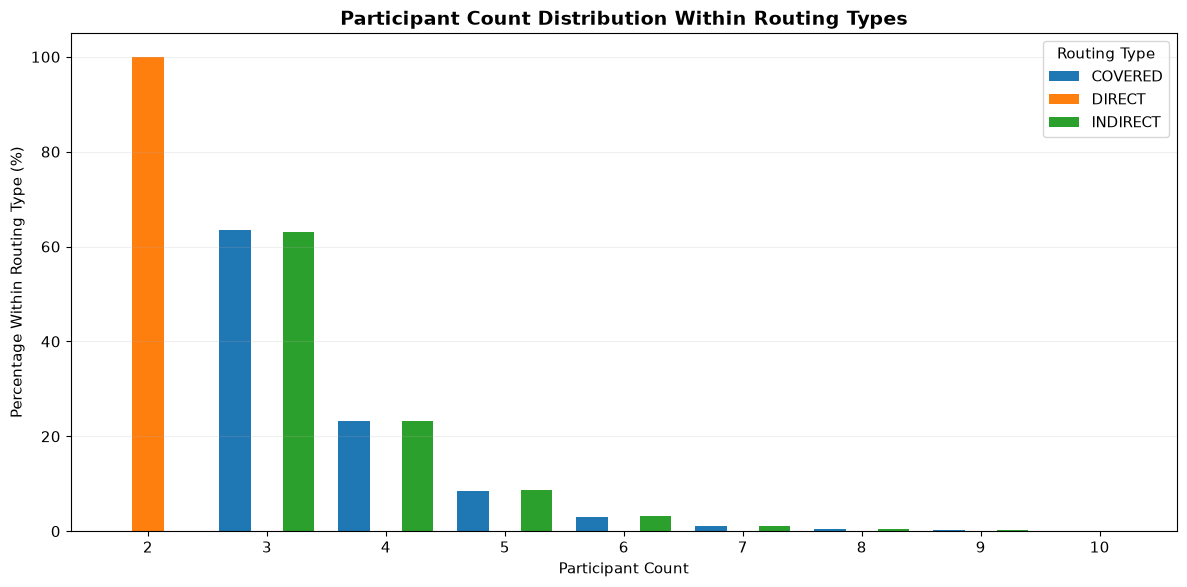

Routing participant distribution chart completed.


In [17]:
# ============================================================
# CELL 14A - ROUTING VS PARTICIPANT COUNT CHART
# Purpose:
# Visualize participant-count distributions within each
# routing type using percentages for fair comparison.
# ============================================================

# ------------------------------------------------------------
# 1. Prepare participant count data
# ------------------------------------------------------------

participant_plot = routing_participant_table.copy()

participant_plot["ROUTE_TOTAL"] = (
    participant_plot.groupby(
        "ROUTING_TYPE"
    )["TRANSACTION_COUNT"].transform("sum")
)

participant_plot["PERCENT"] = (
    participant_plot["TRANSACTION_COUNT"]
    / participant_plot["ROUTE_TOTAL"]
    * 100
)


# ------------------------------------------------------------
# 2. Create a pivot table
# ------------------------------------------------------------

participant_pivot = participant_plot.pivot_table(
    index="PARTICIPANT_COUNT",
    columns="ROUTING_TYPE",
    values="PERCENT",
    aggfunc="sum",
    fill_value=0
)


# ------------------------------------------------------------
# 3. Filter participant counts between 2 and 10
# ------------------------------------------------------------

# Use boolean indexing because pandas Index does not
# support the Series.between() method.

participant_pivot = participant_pivot.loc[
    (participant_pivot.index >= 2)
    & (participant_pivot.index <= 10)
]


# ------------------------------------------------------------
# 4. Create the chart
# ------------------------------------------------------------

ax = participant_pivot.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

ax.set_title(
    "Participant Count Distribution Within Routing Types",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Participant Count")
ax.set_ylabel("Percentage Within Routing Type (%)")

ax.legend(title="Routing Type")
ax.grid(axis="y", alpha=0.2)

plt.xticks(rotation=0)
plt.tight_layout()


# ------------------------------------------------------------
# 5. Export the chart
# ------------------------------------------------------------

export_chart(
    "routing_participant_distribution.png"
)

plt.show()

print("Routing participant distribution chart completed.")

Chart exported: routing_fx_composition.png


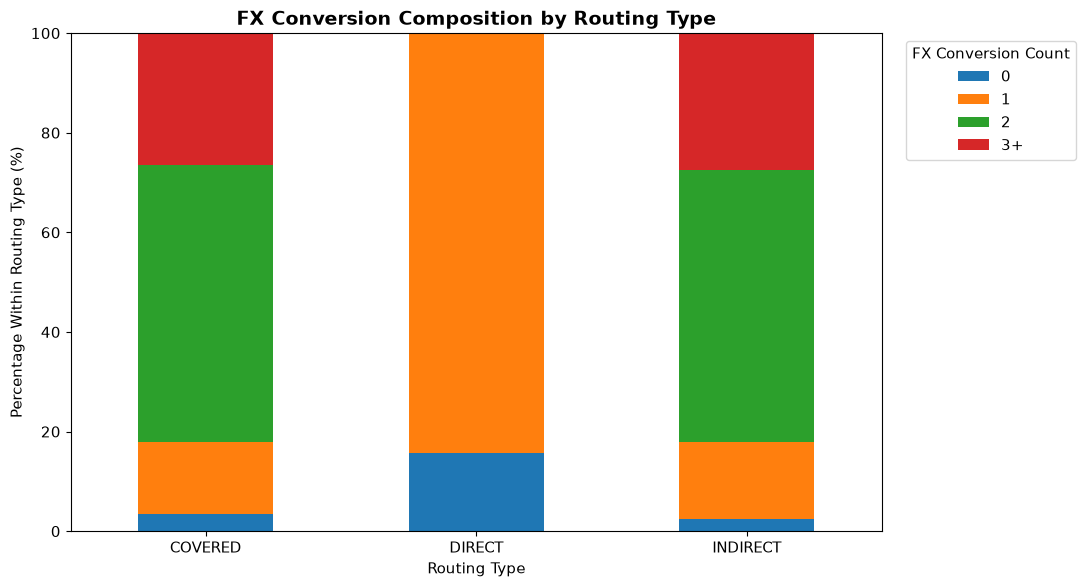

In [18]:
# ============================================================
# CELL 14B - ROUTING VS FX COUNT CHART
# Purpose:
# Compare FX conversion distributions within routing types.
# ============================================================

fx_plot = routing_fx_table.copy()

fx_plot["FX_GROUP"] = np.where(
    fx_plot["FX_COUNT"] >= 3,
    "3+",
    fx_plot["FX_COUNT"].astype(str)
)

fx_grouped = (
    fx_plot.groupby(
        ["ROUTING_TYPE", "FX_GROUP"],
        as_index=False
    )["TRANSACTION_COUNT"].sum()
)

fx_grouped["ROUTE_TOTAL"] = (
    fx_grouped.groupby(
        "ROUTING_TYPE"
    )["TRANSACTION_COUNT"].transform("sum")
)

fx_grouped["PERCENT"] = (
    fx_grouped["TRANSACTION_COUNT"]
    / fx_grouped["ROUTE_TOTAL"]
    * 100
)

fx_pivot = fx_grouped.pivot_table(
    index="ROUTING_TYPE",
    columns="FX_GROUP",
    values="PERCENT",
    fill_value=0
)

fx_order = [
    col for col in ["0", "1", "2", "3+"]
    if col in fx_pivot.columns
]

fx_pivot = fx_pivot[fx_order]

ax = fx_pivot.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6)
)

ax.set_title(
    "FX Conversion Composition by Routing Type",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Routing Type")
ax.set_ylabel("Percentage Within Routing Type (%)")

ax.legend(
    title="FX Conversion Count",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.xticks(rotation=0)
plt.tight_layout()

export_chart(
    "routing_fx_composition.png"
)

plt.show()

Chart exported: routing_gap_by_participant_count.png


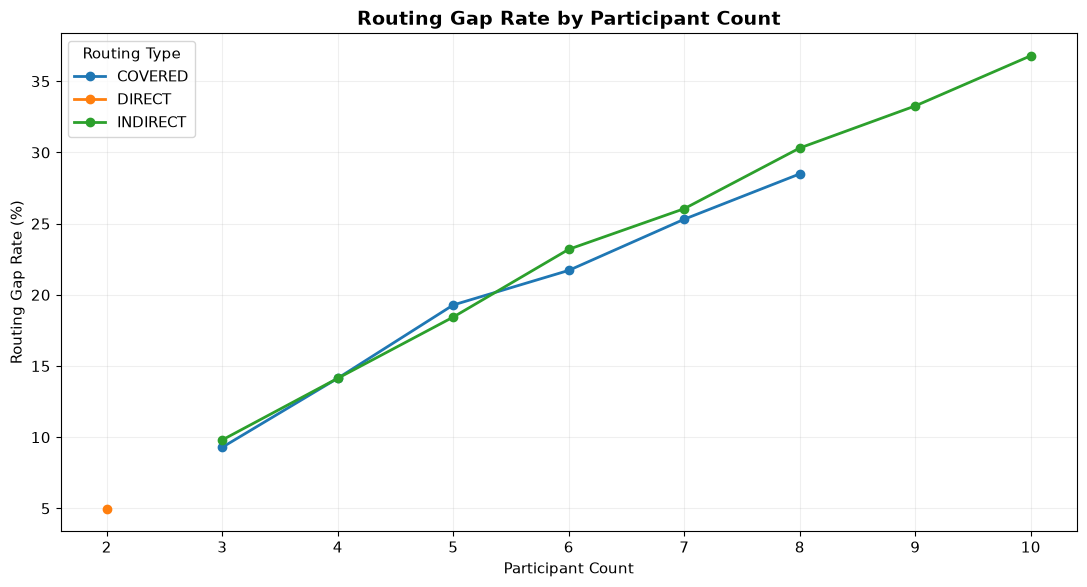

Only groups with at least 100 observable records are displayed. All records remain in the evidence tables.


In [19]:
# ============================================================
# CELL 14C - ROUTING GAP RATE BY PARTICIPANT COUNT
# Purpose:
# Visualize conditional routing gap rates with sample-size
# filtering to avoid highlighting unstable small groups.
# ============================================================

plot_data = gap_by_participant[
    (gap_by_participant["OBSERVABLE_TOTAL"] >= MIN_GROUP_SIZE)
    &
    (gap_by_participant["PARTICIPANT_COUNT"] <= 10)
].copy()

fig, ax = plt.subplots(figsize=(11, 6))

for routing_type, group in plot_data.groupby("ROUTING_TYPE"):

    group = group.sort_values(
        "PARTICIPANT_COUNT"
    )

    ax.plot(
        group["PARTICIPANT_COUNT"],
        group["GAP_RATE_PERCENT"],
        marker="o",
        linewidth=2,
        label=routing_type
    )

ax.set_title(
    "Routing Gap Rate by Participant Count",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Participant Count")
ax.set_ylabel("Routing Gap Rate (%)")

ax.grid(alpha=0.2)
ax.legend(title="Routing Type")

plt.tight_layout()

export_chart(
    "routing_gap_by_participant_count.png"
)

plt.show()

print(
    "Only groups with at least 100 observable records "
    "are displayed. All records remain in the evidence tables."
)

15 — Generate the Bank Routing Rule Register

In [20]:
# ============================================================
# CELL 15 - GENERATE BANK ROUTING RULE REGISTER
# Purpose:
# Organize reconstructed structural relationships,
# supporting evidence, uncertainties, and business relevance.
# ============================================================

rule_register = pd.DataFrame([
    {
        "RULE_ID": "BR01",
        "RULE_FAMILY": "Routing Structure",
        "HYPOTHESIS": "Direct routing implies exactly two participants",
        "EVIDENCE_FILE": "structural_rule_evidence.csv",
        "STATUS": "STRUCTURAL_RELATIONSHIP_OBSERVED",
        "NEXT_TEST": "Verify rule definition and exceptions",
        "BUSINESS_VALUE": "Routing classification consistency"
    },
    {
        "RULE_ID": "BR02",
        "RULE_FAMILY": "FX and Routing",
        "HYPOTHESIS": "FX count >= 2 implies non-direct routing",
        "EVIDENCE_FILE": "structural_rule_evidence.csv",
        "STATUS": "STRUCTURAL_RELATIONSHIP_OBSERVED",
        "NEXT_TEST": "Investigate FX and participant count dependence",
        "BUSINESS_VALUE": "Understand FX routing complexity"
    },
    {
        "RULE_ID": "BR03",
        "RULE_FAMILY": "Routing Structure",
        "HYPOTHESIS": "Two-participant payments are classified as Direct",
        "EVIDENCE_FILE": "structural_rule_evidence.csv",
        "STATUS": "STRUCTURAL_RELATIONSHIP_OBSERVED",
        "NEXT_TEST": "Determine whether this is a definition-based rule",
        "BUSINESS_VALUE": "Routing structure validation"
    },
    {
        "RULE_ID": "BR04",
        "RULE_FAMILY": "Routing Complexity",
        "HYPOTHESIS": (
            "FX conversion distribution depends on participant count"
        ),
        "EVIDENCE_FILE": "fx_distribution_by_participants.csv",
        "STATUS": "REQUIRES_INTERPRETATION",
        "NEXT_TEST": "Identify conditional probabilities and exceptions",
        "BUSINESS_VALUE": "FX complexity monitoring"
    },
    {
        "RULE_ID": "BR05",
        "RULE_FAMILY": "Routing Classification",
        "HYPOTHESIS": (
            "Indirect and Covered share similar participant-FX patterns"
        ),
        "EVIDENCE_FILE": "indirect_covered_matched_comparison.csv",
        "STATUS": "REQUIRES_INTERPRETATION",
        "NEXT_TEST": "Check currency and BIC-specific differences",
        "BUSINESS_VALUE": "Understand Covered routing selection"
    },
    {
        "RULE_ID": "BR06",
        "RULE_FAMILY": "Path Continuity",
        "HYPOTHESIS": (
            "Routing gap probability depends on participant count"
        ),
        "EVIDENCE_FILE": "gap_rate_by_route_and_participants.csv",
        "STATUS": "REQUIRES_INTERPRETATION",
        "NEXT_TEST": "Check nonlinear effects and small groups",
        "BUSINESS_VALUE": "Payment traceability monitoring"
    },
    {
        "RULE_ID": "BR07",
        "RULE_FAMILY": "Path Continuity",
        "HYPOTHESIS": (
            "Routing type has an additional association "
            "with gap probability after adjustment"
        ),
        "EVIDENCE_FILE": "routing_gap_logistic_model.csv",
        "STATUS": "MODEL_ESTIMATED_NOT_CAUSALLY_VALIDATED",
        "NEXT_TEST": "Inspect model assumptions and effect sizes",
        "BUSINESS_VALUE": "Operational visibility monitoring"
    },
    {
        "RULE_ID": "BR08",
        "RULE_FAMILY": "Bank Network",
        "HYPOTHESIS": (
            "Certain BIC pairs have concentrated routing preferences"
        ),
        "EVIDENCE_FILE": "bic_pair_routing_preferences.csv",
        "STATUS": "REQUIRES_INTERPRETATION",
        "NEXT_TEST": "Validate high-volume pair preferences",
        "BUSINESS_VALUE": "Bank-route behaviour monitoring"
    },
    {
        "RULE_ID": "BR09",
        "RULE_FAMILY": "Economic Behaviour",
        "HYPOTHESIS": (
            "Currency and party relationship influence routing patterns"
        ),
        "EVIDENCE_FILE": "currency_party_routing_distribution.csv",
        "STATUS": "REQUIRES_INTERPRETATION",
        "NEXT_TEST": "Stratify by currency, party type, and amount",
        "BUSINESS_VALUE": "Segment-aware routing strategy"
    }
])

rule_register["EFFECT_SIZE"] = ""
rule_register["SCOPE"] = ""
rule_register["EXCEPTIONS"] = ""
rule_register["CONFIDENCE"] = ""
rule_register["FINAL_RULE_STATEMENT"] = ""

rule_register_path = (
    RULE_DIR / "bank_routing_candidate_rules.csv"
)

rule_register.to_csv(
    rule_register_path,
    index=False,
    encoding="utf-8-sig"
)

print("=" * 65)
print("BANK ROUTING RULE REGISTER")
print("=" * 65)

print("Candidate rules:", len(rule_register))
print("Output:", rule_register_path)

display(rule_register)

print("\nCandidate rule register generated.")

BANK ROUTING RULE REGISTER
Candidate rules: 9
Output: c:\Users\user\Documents\UMDAC_datathon\outputs\rules\bank_routing_candidate_rules.csv


,RULE_ID,RULE_FAMILY,HYPOTHESIS,EVIDENCE_FILE,STATUS,NEXT_TEST,BUSINESS_VALUE,EFFECT_SIZE,SCOPE,EXCEPTIONS,CONFIDENCE,FINAL_RULE_STATEMENT
0,BR01,Routing Structure,Direct routing implies exactly two participants,structural_rule_evidence.csv,STRUCTURAL_RELATIONSHIP_OBSERVED,Verify rule definition and exceptions,Routing classification consistency,,,,,
1,BR02,FX and Routing,FX count >= 2 implies non-direct routing,structural_rule_evidence.csv,STRUCTURAL_RELATIONSHIP_OBSERVED,Investigate FX and participant count dependence,Understand FX routing complexity,,,,,
2,BR03,Routing Structure,Two-participant payments are classified as Direct,structural_rule_evidence.csv,STRUCTURAL_RELATIONSHIP_OBSERVED,Determine whether this is a definition-based rule,Routing structure validation,,,,,
3,BR04,Routing Complexity,FX conversion distribution depends on particip...,fx_distribution_by_participants.csv,REQUIRES_INTERPRETATION,Identify conditional probabilities and exceptions,FX complexity monitoring,,,,,
4,BR05,Routing Classification,Indirect and Covered share similar participant...,indirect_covered_matched_comparison.csv,REQUIRES_INTERPRETATION,Check currency and BIC-specific differences,Understand Covered routing selection,,,,,
5,BR06,Path Continuity,Routing gap probability depends on participant...,gap_rate_by_route_and_participants.csv,REQUIRES_INTERPRETATION,Check nonlinear effects and small groups,Payment traceability monitoring,,,,,
6,BR07,Path Continuity,Routing type has an additional association wit...,routing_gap_logistic_model.csv,MODEL_ESTIMATED_NOT_CAUSALLY_VALIDATED,Inspect model assumptions and effect sizes,Operational visibility monitoring,,,,,
7,BR08,Bank Network,Certain BIC pairs have concentrated routing pr...,bic_pair_routing_preferences.csv,REQUIRES_INTERPRETATION,Validate high-volume pair preferences,Bank-route behaviour monitoring,,,,,
8,BR09,Economic Behaviour,Currency and party relationship influence rout...,currency_party_routing_distribution.csv,REQUIRES_INTERPRETATION,"Stratify by currency, party type, and amount",Segment-aware routing strategy,,,,,



Candidate rule register generated.


16 — Final Integrity and Consistency Validation

In [21]:
# ============================================================
# CELL 16 - FINAL ROUTING ANALYSIS VALIDATION
# Purpose:
# Verify complete record coverage and consistency across
# routing evidence tables before reporting findings.
# ============================================================

validation_checks = []

def add_check(name, actual, expected):

    validation_checks.append({
        "CHECK": name,
        "ACTUAL": int(actual),
        "EXPECTED": int(expected),
        "PASSED": int(actual) == int(expected)
    })


# ------------------------------------------------------------
# 1. Validate record totals
# ------------------------------------------------------------

add_check(
    "Routing distribution",
    routing_table["TRANSACTION_COUNT"].sum(),
    EXPECTED_RECORDS
)

add_check(
    "Routing by participants",
    routing_participant_table["TRANSACTION_COUNT"].sum(),
    EXPECTED_RECORDS
)

add_check(
    "Routing by FX",
    routing_fx_table["TRANSACTION_COUNT"].sum(),
    EXPECTED_RECORDS
)

add_check(
    "Routing by participants and FX",
    routing_participant_fx_table["TRANSACTION_COUNT"].sum(),
    EXPECTED_RECORDS
)

add_check(
    "Routing by path gap",
    routing_gap_table["TRANSACTION_COUNT"].sum(),
    EXPECTED_RECORDS
)

add_check(
    "Routing by currency and party",
    routing_currency_party_table["TRANSACTION_COUNT"].sum(),
    EXPECTED_RECORDS
)

add_check(
    "Routing by BIC pair",
    bic_pair_route_table["TRANSACTION_COUNT"].sum(),
    EXPECTED_RECORDS
)


# ------------------------------------------------------------
# 2. Validate known routing gap count
# ------------------------------------------------------------

observed_gap_count = routing_gap_table.loc[
    routing_gap_table["HAS_PATH_GAP"] == "Y",
    "TRANSACTION_COUNT"
].sum()

add_check(
    "Routing path gaps",
    observed_gap_count,
    80_504
)


# ------------------------------------------------------------
# 3. Validate BIC path scan coverage
# ------------------------------------------------------------

add_check(
    "BIC path inspection",
    path_stats["TOTAL"],
    EXPECTED_RECORDS
)


# ------------------------------------------------------------
# 4. Create validation report
# ------------------------------------------------------------

validation_df = pd.DataFrame(validation_checks)

display(validation_df)

assert validation_df["PASSED"].all(), (
    "One or more routing analysis validation checks failed."
)

export_table(
    validation_df,
    "routing_analysis_validation.csv"
)


# ------------------------------------------------------------
# 5. Display summary
# ------------------------------------------------------------

print("=" * 65)
print("BANK ROUTING ANALYSIS VALIDATION")
print("=" * 65)

print("Dataset records:", f"{EXPECTED_RECORDS:,}")
print("Routing gap records:", f"{observed_gap_count:,}")
print("Candidate rules:", len(rule_register))

print("\nValidation status: PASSED")
print("Original transaction records were not modified.")
print("Evidence outputs are ready for rule review.")

,CHECK,ACTUAL,EXPECTED,PASSED
0,Routing distribution,1048575,1048575,True
1,Routing by participants,1048575,1048575,True
2,Routing by FX,1048575,1048575,True
3,Routing by participants and FX,1048575,1048575,True
4,Routing by path gap,1048575,1048575,True
5,Routing by currency and party,1048575,1048575,True
6,Routing by BIC pair,1048575,1048575,True
7,Routing path gaps,80504,80504,True
8,BIC path inspection,1048575,1048575,True


Exported: routing_analysis_validation.csv
BANK ROUTING ANALYSIS VALIDATION
Dataset records: 1,048,575
Routing gap records: 80,504
Candidate rules: 9

Validation status: PASSED
Original transaction records were not modified.
Evidence outputs are ready for rule review.


In [24]:
# ============================================================
# CELL 17 - ADVANCED ROUTING VALIDATION SETUP
# Purpose:
# Prepare reusable evidence tables and output directories
# for advanced routing rule investigations.
# ============================================================

from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import minimize_scalar

# ------------------------------------------------------------
# 1. Verify existing notebook variables
# ------------------------------------------------------------

required_variables = [
    "PROJECT_ROOT",
    "DATA_PATH",
    "CHUNK_SIZE",
    "EXPECTED_RECORDS",
    "participant_fx_table",
    "routing_participant_fx_table",
    "gap_by_participant",
    "bic_pair_route_table"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

assert not missing_variables, (
    f"Missing variables: {missing_variables}"
)

assert Path(DATA_PATH).is_file(), (
    "Cleaned dataset was not found."
)

# ------------------------------------------------------------
# 2. Create advanced validation directories
# ------------------------------------------------------------

ADV_TABLE_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "routing"
    / "advanced"
)

ADV_CHART_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "charts"
    / "routing"
    / "advanced"
)

ADV_TABLE_DIR.mkdir(parents=True, exist_ok=True)
ADV_CHART_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 3. Define reusable export functions
# ------------------------------------------------------------

def save_advanced_table(df, filename):

    path = ADV_TABLE_DIR / filename

    df.to_csv(
        path,
        index=False,
        encoding="utf-8-sig"
    )

    print("Saved table:", filename)


def save_advanced_chart(filename):

    path = ADV_CHART_DIR / filename

    plt.savefig(
        path,
        dpi=200,
        bbox_inches="tight"
    )

    print("Saved chart:", filename)


# ------------------------------------------------------------
# 4. Configure analysis thresholds
# ------------------------------------------------------------

MIN_RELIABLE_GROUP = 100
MIN_CURRENCY_RECORDS = 500
MIN_BIC_PAIR_RECORDS = 100

print("=" * 65)
print("ADVANCED BANK ROUTING VALIDATION")
print("=" * 65)

print("Dataset:", DATA_PATH)
print("Advanced tables:", ADV_TABLE_DIR)
print("Advanced charts:", ADV_CHART_DIR)

print("\nAll required variables are available.")
print("Advanced validation setup completed.")

ADVANCED BANK ROUTING VALIDATION
Dataset: c:\Users\user\Documents\UMDAC_datathon\data\cleaned\swift_payments_cleaned.csv
Advanced tables: c:\Users\user\Documents\UMDAC_datathon\outputs\tables\routing\advanced
Advanced charts: c:\Users\user\Documents\UMDAC_datathon\outputs\charts\routing\advanced

All required variables are available.
Advanced validation setup completed.


In [25]:
# ============================================================
# CELL 18 - FX STRUCTURAL CONSTRAINT VALIDATION
# Purpose:
# Test whether FX conversion count is always bounded
# by participant count minus one.
# ============================================================

# ------------------------------------------------------------
# 1. Prepare the complete participant-FX aggregation
# ------------------------------------------------------------

fx_constraint = routing_participant_fx_table.copy()

fx_constraint["MAX_ALLOWED_FX"] = (
    fx_constraint["PARTICIPANT_COUNT"] - 1
)

fx_constraint["CONSTRAINT_SATISFIED"] = (
    (fx_constraint["PARTICIPANT_COUNT"] >= 2)
    &
    (fx_constraint["FX_COUNT"] >= 0)
    &
    (
        fx_constraint["FX_COUNT"]
        <= fx_constraint["MAX_ALLOWED_FX"]
    )
)

fx_constraint["EXCESS_FX_STEPS"] = (
    fx_constraint["FX_COUNT"]
    - fx_constraint["MAX_ALLOWED_FX"]
)

# ------------------------------------------------------------
# 2. Calculate support, scope, and exceptions
# ------------------------------------------------------------

total_scope = int(
    fx_constraint["TRANSACTION_COUNT"].sum()
)

supported_records = int(
    fx_constraint.loc[
        fx_constraint["CONSTRAINT_SATISFIED"],
        "TRANSACTION_COUNT"
    ].sum()
)

exception_records = total_scope - supported_records

support_percentage = (
    supported_records / total_scope * 100
)

# ------------------------------------------------------------
# 3. Calculate evidence within each routing type
# ------------------------------------------------------------

route_evidence = (
    fx_constraint
    .groupby("ROUTING_TYPE")
    .apply(
        lambda g: pd.Series({
            "TOTAL_RECORDS": int(
                g["TRANSACTION_COUNT"].sum()
            ),
            "SUPPORTED_RECORDS": int(
                g.loc[
                    g["CONSTRAINT_SATISFIED"],
                    "TRANSACTION_COUNT"
                ].sum()
            )
        }),
        include_groups=False
    )
    .reset_index()
)

route_evidence["EXCEPTIONS"] = (
    route_evidence["TOTAL_RECORDS"]
    - route_evidence["SUPPORTED_RECORDS"]
)

route_evidence["SUPPORT_PERCENT"] = (
    route_evidence["SUPPORTED_RECORDS"]
    / route_evidence["TOTAL_RECORDS"]
    * 100
)

# ------------------------------------------------------------
# 4. Report observed FX ranges by participant count
# ------------------------------------------------------------

valid_groups = fx_constraint[
    fx_constraint["TRANSACTION_COUNT"] > 0
].copy()

fx_bounds = (
    valid_groups
    .groupby("PARTICIPANT_COUNT")
    .agg(
        MIN_OBSERVED_FX=("FX_COUNT", "min"),
        MAX_OBSERVED_FX=("FX_COUNT", "max"),
        RECORDS=("TRANSACTION_COUNT", "sum")
    )
    .reset_index()
)

fx_bounds["THEORETICAL_MAX_FX"] = (
    fx_bounds["PARTICIPANT_COUNT"] - 1
)

fx_bounds["REACHES_UPPER_BOUND"] = (
    fx_bounds["MAX_OBSERVED_FX"]
    == fx_bounds["THEORETICAL_MAX_FX"]
)

# ------------------------------------------------------------
# 5. Export detailed evidence
# ------------------------------------------------------------

exception_groups = fx_constraint[
    ~fx_constraint["CONSTRAINT_SATISFIED"]
].copy()

save_advanced_table(
    fx_constraint,
    "fx_structural_constraint_all_groups.csv"
)

save_advanced_table(
    exception_groups,
    "fx_structural_constraint_exceptions.csv"
)

save_advanced_table(
    route_evidence,
    "fx_constraint_by_routing.csv"
)

save_advanced_table(
    fx_bounds,
    "fx_observed_upper_bounds.csv"
)

# ------------------------------------------------------------
# 6. Display results
# ------------------------------------------------------------

print("=" * 65)
print("FX STRUCTURAL CONSTRAINT VALIDATION")
print("=" * 65)

print("Rule: FX_COUNT <= PARTICIPANT_COUNT - 1")
print("Scope:", f"{total_scope:,}")
print("Supported:", f"{supported_records:,}")
print("Exceptions:", f"{exception_records:,}")
print("Support:", f"{support_percentage:.4f}%")

print("\nEvidence by Routing Type:")
display(route_evidence)

print("\nObserved FX Bounds:")
display(fx_bounds)

print("\nException Groups:")
display(exception_groups)

print("\nFX constraint validation completed.")

Saved table: fx_structural_constraint_all_groups.csv
Saved table: fx_structural_constraint_exceptions.csv
Saved table: fx_constraint_by_routing.csv
Saved table: fx_observed_upper_bounds.csv
FX STRUCTURAL CONSTRAINT VALIDATION
Rule: FX_COUNT <= PARTICIPANT_COUNT - 1
Scope: 1,048,575
Supported: 1,048,575
Exceptions: 0
Support: 100.0000%

Evidence by Routing Type:


,ROUTING_TYPE,TOTAL_RECORDS,SUPPORTED_RECORDS,EXCEPTIONS,SUPPORT_PERCENT
0,COVERED,43578,43578,0,100.0
1,DIRECT,662245,662245,0,100.0
2,INDIRECT,342752,342752,0,100.0



Observed FX Bounds:


,PARTICIPANT_COUNT,MIN_OBSERVED_FX,MAX_OBSERVED_FX,RECORDS,THEORETICAL_MAX_FX,REACHES_UPPER_BOUND
0,2,0,1,662245,1,True
1,3,0,2,243986,2,True
2,4,0,3,89703,3,True
3,5,0,4,33230,4,True
4,6,0,5,12229,5,True
5,7,0,6,4551,6,True
6,8,0,7,1654,7,True
7,9,3,8,601,8,True
8,10,5,9,241,9,True
9,11,4,10,90,10,True



Exception Groups:


,ROUTING_TYPE,PARTICIPANT_COUNT,FX_COUNT,TRANSACTION_COUNT,MAX_ALLOWED_FX,CONSTRAINT_SATISFIED,EXCESS_FX_STEPS



FX constraint validation completed.


Saved table: gap_mechanism_observed_vs_predicted.csv
Saved table: gap_mechanism_model_comparison.csv
Saved table: gap_mechanism_estimated_probabilities.csv
Saved chart: gap_mechanism_observed_vs_predicted.png


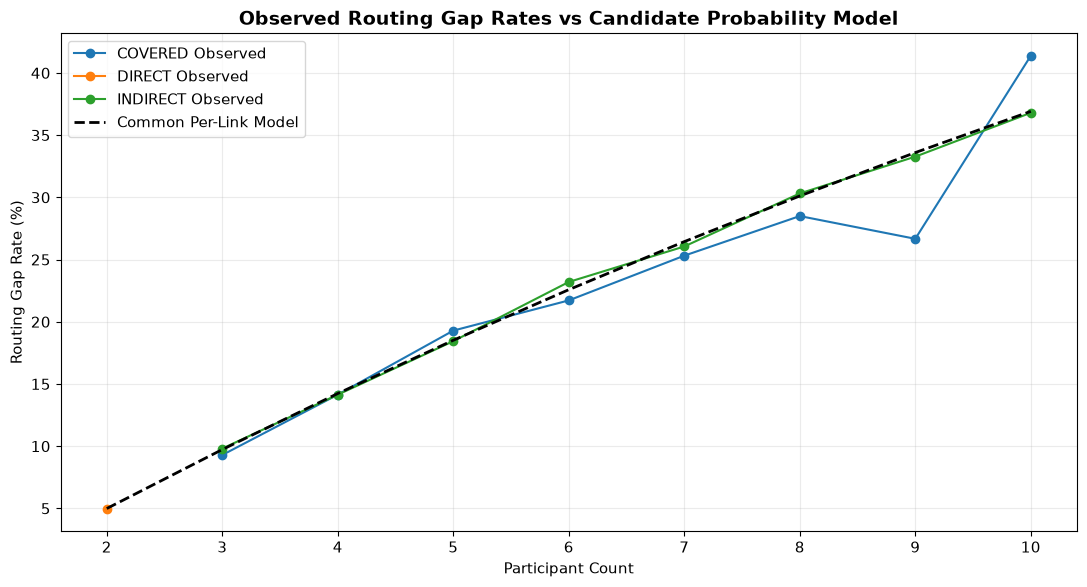

ROUTING GAP MECHANISM VALIDATION
Estimated common per-link probability: 0.049890

Routing-specific probabilities:


,ROUTING_TYPE,ESTIMATED_LINK_PROBABILITY
0,ALL,0.049890
1,COVERED,0.048678
2,DIRECT,0.049892
3,INDIRECT,0.050043



Model comparison:


,MODEL,PARAMETERS,WEIGHTED_MAE_PP,WEIGHTED_RMSE_PP
0,Common per-link probability,1,0.051496,0.141525
1,Routing-specific per-link probability,3,0.045361,0.131406



Observed vs predicted:


HAS_PATH_GAP,ROUTING_TYPE,PARTICIPANT_COUNT,OBSERVABLE_TOTAL,OBSERVED_GAP_PERCENT,COMMON_PREDICTED_PERCENT,COMMON_ERROR_PP
0,COVERED,3,27628,9.291299,9.729183,0.437885
1,COVERED,4,10091,14.141314,14.232835,0.091521
2,COVERED,5,3733,19.287436,18.511797,-0.775640
3,COVERED,6,1340,21.716418,22.577279,0.860861
4,COVERED,7,482,25.311203,26.439933,1.128730
5,COVERED,8,186,28.494624,30.109878,1.615254
6,COVERED,9,75,26.666667,33.596727,6.930060
7,COVERED,10,29,41.379310,36.909616,-4.469694
11,DIRECT,2,662245,4.989241,4.989044,-0.000197
12,INDIRECT,3,216358,9.806894,9.729183,-0.077711



Routing gap mechanism analysis completed.


In [26]:
# ============================================================
# CELL 19 - ROUTING GAP MECHANISM VALIDATION
# Purpose:
# Test whether routing gap rates follow an independent
# per-link probability model.
#
# Hypothesis:
# P(at least one gap | n participants)
# = 1 - (1 - p) ** (n - 1)
# ============================================================

from scipy.optimize import minimize_scalar

# ------------------------------------------------------------
# 1. Prepare observed gap evidence
# ------------------------------------------------------------

gap_evidence = gap_by_participant.copy()

gap_evidence = gap_evidence[
    (gap_evidence["PARTICIPANT_COUNT"] >= 2)
    &
    (gap_evidence["PARTICIPANT_COUNT"] <= 10)
    &
    (gap_evidence["OBSERVABLE_TOTAL"] > 0)
].copy()

gap_evidence["OBSERVED_GAP_RATE"] = (
    gap_evidence["Y"]
    / gap_evidence["OBSERVABLE_TOTAL"]
)

# ------------------------------------------------------------
# 2. Define the candidate probability model
# ------------------------------------------------------------

def predict_gap_probability(participants, p):

    return 1 - (1 - p) ** (participants - 1)


def fit_link_probability(data):

    n = data["PARTICIPANT_COUNT"].to_numpy(
        dtype=float
    )

    gap_count = data["Y"].to_numpy(
        dtype=float
    )

    total_count = data["OBSERVABLE_TOTAL"].to_numpy(
        dtype=float
    )

    def negative_log_likelihood(p):

        probability = predict_gap_probability(n, p)

        probability = np.clip(
            probability,
            1e-12,
            1 - 1e-12
        )

        log_likelihood = (
            gap_count * np.log(probability)
            +
            (total_count - gap_count)
            * np.log(1 - probability)
        ).sum()

        return -log_likelihood

    result = minimize_scalar(
        negative_log_likelihood,
        bounds=(1e-6, 0.5),
        method="bounded",
        options={"xatol": 1e-12}
    )

    if not result.success:
        raise RuntimeError(
            "Per-link probability optimization failed."
        )

    return float(result.x)


# ------------------------------------------------------------
# 3. Fit one common probability for all routing types
# ------------------------------------------------------------

common_link_probability = fit_link_probability(
    gap_evidence
)

gap_evidence["COMMON_MODEL_PREDICTION"] = (
    predict_gap_probability(
        gap_evidence["PARTICIPANT_COUNT"],
        common_link_probability
    )
)

# ------------------------------------------------------------
# 4. Fit separate probabilities for each routing type
# ------------------------------------------------------------

route_link_probabilities = {}

for route, group in gap_evidence.groupby("ROUTING_TYPE"):

    route_link_probabilities[route] = (
        fit_link_probability(group)
    )

gap_evidence["ROUTE_LINK_PROBABILITY"] = (
    gap_evidence["ROUTING_TYPE"]
    .map(route_link_probabilities)
)

gap_evidence["ROUTE_MODEL_PREDICTION"] = (
    predict_gap_probability(
        gap_evidence["PARTICIPANT_COUNT"],
        gap_evidence["ROUTE_LINK_PROBABILITY"]
    )
)

# ------------------------------------------------------------
# 5. Calculate prediction errors
# ------------------------------------------------------------

gap_evidence["COMMON_ERROR_PP"] = (
    gap_evidence["COMMON_MODEL_PREDICTION"]
    - gap_evidence["OBSERVED_GAP_RATE"]
) * 100

gap_evidence["ROUTE_ERROR_PP"] = (
    gap_evidence["ROUTE_MODEL_PREDICTION"]
    - gap_evidence["OBSERVED_GAP_RATE"]
) * 100

gap_evidence["OBSERVED_GAP_PERCENT"] = (
    gap_evidence["OBSERVED_GAP_RATE"] * 100
)

gap_evidence["COMMON_PREDICTED_PERCENT"] = (
    gap_evidence["COMMON_MODEL_PREDICTION"] * 100
)

gap_evidence["ROUTE_PREDICTED_PERCENT"] = (
    gap_evidence["ROUTE_MODEL_PREDICTION"] * 100
)

# ------------------------------------------------------------
# 6. Calculate weighted model errors
# ------------------------------------------------------------

weights = gap_evidence["OBSERVABLE_TOTAL"]

common_weighted_mae = np.average(
    np.abs(gap_evidence["COMMON_ERROR_PP"]),
    weights=weights
)

route_weighted_mae = np.average(
    np.abs(gap_evidence["ROUTE_ERROR_PP"]),
    weights=weights
)

common_weighted_rmse = np.sqrt(
    np.average(
        gap_evidence["COMMON_ERROR_PP"] ** 2,
        weights=weights
    )
)

route_weighted_rmse = np.sqrt(
    np.average(
        gap_evidence["ROUTE_ERROR_PP"] ** 2,
        weights=weights
    )
)

# ------------------------------------------------------------
# 7. Prepare model comparison
# ------------------------------------------------------------

gap_model_comparison = pd.DataFrame([
    {
        "MODEL": "Common per-link probability",
        "PARAMETERS": 1,
        "WEIGHTED_MAE_PP": common_weighted_mae,
        "WEIGHTED_RMSE_PP": common_weighted_rmse
    },
    {
        "MODEL": "Routing-specific per-link probability",
        "PARAMETERS": len(route_link_probabilities),
        "WEIGHTED_MAE_PP": route_weighted_mae,
        "WEIGHTED_RMSE_PP": route_weighted_rmse
    }
])

link_probability_table = pd.DataFrame([
    {
        "ROUTING_TYPE": "ALL",
        "ESTIMATED_LINK_PROBABILITY": (
            common_link_probability
        )
    }
] + [
    {
        "ROUTING_TYPE": route,
        "ESTIMATED_LINK_PROBABILITY": probability
    }
    for route, probability
    in route_link_probabilities.items()
])

# ------------------------------------------------------------
# 8. Export evidence
# ------------------------------------------------------------

save_advanced_table(
    gap_evidence,
    "gap_mechanism_observed_vs_predicted.csv"
)

save_advanced_table(
    gap_model_comparison,
    "gap_mechanism_model_comparison.csv"
)

save_advanced_table(
    link_probability_table,
    "gap_mechanism_estimated_probabilities.csv"
)

# ------------------------------------------------------------
# 9. Visualize observed and predicted gap rates
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 6))

for route, group in gap_evidence.groupby("ROUTING_TYPE"):

    group = group.sort_values("PARTICIPANT_COUNT")

    ax.plot(
        group["PARTICIPANT_COUNT"],
        group["OBSERVED_GAP_PERCENT"],
        marker="o",
        label=f"{route} Observed"
    )

participant_range = np.arange(2, 11)

common_predictions = predict_gap_probability(
    participant_range,
    common_link_probability
) * 100

ax.plot(
    participant_range,
    common_predictions,
    linestyle="--",
    linewidth=2,
    color="black",
    label="Common Per-Link Model"
)

ax.set_title(
    "Observed Routing Gap Rates vs Candidate Probability Model",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Participant Count")
ax.set_ylabel("Routing Gap Rate (%)")

ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()

save_advanced_chart(
    "gap_mechanism_observed_vs_predicted.png"
)

plt.show()

# ------------------------------------------------------------
# 10. Display results
# ------------------------------------------------------------

print("=" * 65)
print("ROUTING GAP MECHANISM VALIDATION")
print("=" * 65)

print(
    "Estimated common per-link probability:",
    f"{common_link_probability:.6f}"
)

print("\nRouting-specific probabilities:")
display(link_probability_table)

print("\nModel comparison:")
display(gap_model_comparison)

print("\nObserved vs predicted:")
display(
    gap_evidence[
        [
            "ROUTING_TYPE",
            "PARTICIPANT_COUNT",
            "OBSERVABLE_TOTAL",
            "OBSERVED_GAP_PERCENT",
            "COMMON_PREDICTED_PERCENT",
            "COMMON_ERROR_PP"
        ]
    ]
)

print("\nRouting gap mechanism analysis completed.")

In [27]:
# ============================================================
# CELL 20 - BIC ENDPOINT MISMATCH INVESTIGATION
# Purpose:
# Investigate path endpoint mismatches by routing type,
# gap status, and endpoint position.
# ============================================================

from collections import Counter

# ------------------------------------------------------------
# 1. Define required columns
# ------------------------------------------------------------

ENDPOINT_COLUMNS = [
    "ORDERING_BIC8",
    "BENEFICIARY_BIC8",
    "BIC8_PATH",
    "TRANSACTION_TYPE_CODE_STD",
    "HAS_PATH_GAP"
]

endpoint_counter = Counter()

scanned_records = 0

# ------------------------------------------------------------
# 2. Scan the complete dataset
# ------------------------------------------------------------

reader = pd.read_csv(
    DATA_PATH,
    usecols=ENDPOINT_COLUMNS,
    dtype=str,
    keep_default_na=False,
    na_filter=False,
    chunksize=CHUNK_SIZE
)

for chunk_number, chunk in enumerate(reader, start=1):

    scanned_records += len(chunk)

    # Normalize values in the working chunk only
    chunk["ROUTING_TYPE"] = (
        chunk["TRANSACTION_TYPE_CODE_STD"]
        .str.strip()
        .str.upper()
    )

    ordering_bic = chunk["ORDERING_BIC8"].str.strip()

    beneficiary_bic = (
        chunk["BENEFICIARY_BIC8"].str.strip()
    )

    # Split routing paths into ordered tokens
    path_tokens = chunk["BIC8_PATH"].str.split(";")

    first_bic = (
        path_tokens.str[0]
        .fillna("")
        .str.strip()
    )

    last_bic = (
        path_tokens.str[-1]
        .fillna("")
        .str.strip()
    )

    # --------------------------------------------------------
    # 3. Identify endpoint matches
    # --------------------------------------------------------

    chunk["START_MATCH"] = (
        first_bic == ordering_bic
    )

    chunk["END_MATCH"] = (
        last_bic == beneficiary_bic
    )

    chunk["START_MISMATCH"] = (
        ~chunk["START_MATCH"]
    )

    chunk["END_MISMATCH"] = (
        ~chunk["END_MATCH"]
    )

    chunk["ANY_ENDPOINT_MISMATCH"] = (
        chunk["START_MISMATCH"]
        |
        chunk["END_MISMATCH"]
    )

    chunk["BOTH_ENDPOINTS_MISMATCH"] = (
        chunk["START_MISMATCH"]
        &
        chunk["END_MISMATCH"]
    )

    # --------------------------------------------------------
    # 4. Classify gap status
    # --------------------------------------------------------

    chunk["GAP_STATUS"] = np.where(
        chunk["BIC8_PATH"].str.contains(
            "...",
            regex=False,
            na=False
        ),
        "GAP",
        "COMPLETE"
    )

    chunk["GAP_AT_START"] = first_bic.eq("...")
    chunk["GAP_AT_END"] = last_bic.eq("...")

    # --------------------------------------------------------
    # 5. Aggregate mismatch indicators
    # --------------------------------------------------------

    indicators = [
        "START_MISMATCH",
        "END_MISMATCH",
        "ANY_ENDPOINT_MISMATCH",
        "BOTH_ENDPOINTS_MISMATCH",
        "GAP_AT_START",
        "GAP_AT_END"
    ]

    grouped = (
        chunk.groupby(
            ["ROUTING_TYPE", "GAP_STATUS"],
            dropna=False
        )[indicators]
        .agg(["sum", "count"])
    )

    for (routing_type, gap_status), row in grouped.iterrows():

        key = (routing_type, gap_status)

        endpoint_counter[
            key + ("TOTAL_RECORDS",)
        ] += int(row[("START_MISMATCH", "count")])

        for indicator in indicators:

            endpoint_counter[
                key + (indicator,)
            ] += int(row[(indicator, "sum")])

    if chunk_number % 10 == 0:
        print(
            f"Chunk {chunk_number}: "
            f"{scanned_records:,} records inspected"
        )

# ------------------------------------------------------------
# 6. Convert aggregated results into a table
# ------------------------------------------------------------

endpoint_rows = []

group_keys = sorted({
    key[:2]
    for key in endpoint_counter
})

for routing_type, gap_status in group_keys:

    key = (routing_type, gap_status)

    total = endpoint_counter[
        key + ("TOTAL_RECORDS",)
    ]

    row = {
        "ROUTING_TYPE": routing_type,
        "GAP_STATUS": gap_status,
        "TOTAL_RECORDS": total
    }

    for indicator in [
        "START_MISMATCH",
        "END_MISMATCH",
        "ANY_ENDPOINT_MISMATCH",
        "BOTH_ENDPOINTS_MISMATCH",
        "GAP_AT_START",
        "GAP_AT_END"
    ]:

        count = endpoint_counter[
            key + (indicator,)
        ]

        row[indicator + "_COUNT"] = count

        row[indicator + "_RATE_PERCENT"] = (
            count / total * 100
            if total > 0 else np.nan
        )

    endpoint_rows.append(row)

endpoint_analysis = pd.DataFrame(endpoint_rows)

# ------------------------------------------------------------
# 7. Validate the complete dataset coverage
# ------------------------------------------------------------

assert scanned_records == EXPECTED_RECORDS

assert (
    endpoint_analysis["TOTAL_RECORDS"].sum()
    == EXPECTED_RECORDS
)

total_start_mismatch = int(
    endpoint_analysis["START_MISMATCH_COUNT"].sum()
)

total_end_mismatch = int(
    endpoint_analysis["END_MISMATCH_COUNT"].sum()
)

assert total_start_mismatch == 52_060, (
    "Start mismatch count differs from the previous audit."
)

assert total_end_mismatch == 52_390, (
    "End mismatch count differs from the previous audit."
)

# ------------------------------------------------------------
# 8. Export and display evidence
# ------------------------------------------------------------

save_advanced_table(
    endpoint_analysis,
    "bic_endpoint_mismatch_by_route_and_gap.csv"
)

print("=" * 65)
print("BIC ENDPOINT MISMATCH INVESTIGATION")
print("=" * 65)

print("Records inspected:", f"{scanned_records:,}")

print(
    "Start mismatches:",
    f"{total_start_mismatch:,}"
)

print(
    "End mismatches:",
    f"{total_end_mismatch:,}"
)

display(endpoint_analysis)

print("\nBIC endpoint investigation completed.")

Chunk 10: 250,000 records inspected
Chunk 20: 500,000 records inspected
Chunk 30: 750,000 records inspected
Chunk 40: 1,000,000 records inspected
Saved table: bic_endpoint_mismatch_by_route_and_gap.csv
BIC ENDPOINT MISMATCH INVESTIGATION
Records inspected: 1,048,575
Start mismatches: 52,060
End mismatches: 52,390


,ROUTING_TYPE,GAP_STATUS,TOTAL_RECORDS,START_MISMATCH_COUNT,START_MISMATCH_RATE_PERCENT,END_MISMATCH_COUNT,END_MISMATCH_RATE_PERCENT,ANY_ENDPOINT_MISMATCH_COUNT,ANY_ENDPOINT_MISMATCH_RATE_PERCENT,BOTH_ENDPOINTS_MISMATCH_COUNT,BOTH_ENDPOINTS_MISMATCH_RATE_PERCENT,GAP_AT_START_COUNT,GAP_AT_START_RATE_PERCENT,GAP_AT_END_COUNT,GAP_AT_END_RATE_PERCENT
0,COVERED,COMPLETE,38363,1856,4.837995,1945,5.069989,3710,9.670777,91,0.237208,0,0.0,0,0.0
1,COVERED,GAP,5215,260,4.985618,249,4.774688,497,9.530201,12,0.230105,0,0.0,0,0.0
2,DIRECT,COMPLETE,629204,31365,4.984870,31404,4.991068,61236,9.732297,1533,0.243641,0,0.0,0,0.0
3,DIRECT,GAP,33041,1587,4.803123,1642,4.969583,3152,9.539663,77,0.233044,0,0.0,0,0.0
4,INDIRECT,COMPLETE,300504,14905,4.960001,15038,5.004260,29182,9.711019,761,0.253241,0,0.0,0,0.0
5,INDIRECT,GAP,42248,2087,4.939879,2112,4.999053,4103,9.711702,96,0.227230,0,0.0,0,0.0



BIC endpoint investigation completed.


In [28]:
# ============================================================
# CELL 20B - ENDPOINT MISMATCH INDEPENDENCE CHECK
# Purpose:
# Compare observed endpoint mismatch frequencies with
# the expected values under an independence assumption.
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Aggregate endpoint mismatch counts
# ------------------------------------------------------------

total = int(
    endpoint_analysis["TOTAL_RECORDS"].sum()
)

start_count = int(
    endpoint_analysis["START_MISMATCH_COUNT"].sum()
)

end_count = int(
    endpoint_analysis["END_MISMATCH_COUNT"].sum()
)

both_count = int(
    endpoint_analysis["BOTH_ENDPOINTS_MISMATCH_COUNT"].sum()
)

any_count = int(
    endpoint_analysis["ANY_ENDPOINT_MISMATCH_COUNT"].sum()
)

# ------------------------------------------------------------
# 2. Calculate observed probabilities
# ------------------------------------------------------------

p_start = start_count / total
p_end = end_count / total

p_both_observed = both_count / total
p_any_observed = any_count / total

# ------------------------------------------------------------
# 3. Calculate expected probabilities
# ------------------------------------------------------------

p_both_expected = p_start * p_end

p_any_expected = (
    p_start + p_end - p_both_expected
)

# ------------------------------------------------------------
# 4. Compare observations against independence
# ------------------------------------------------------------

results = pd.DataFrame([
    {
        "METRIC": "Start mismatch",
        "OBSERVED_PERCENT": p_start * 100,
        "EXPECTED_PERCENT": np.nan
    },
    {
        "METRIC": "End mismatch",
        "OBSERVED_PERCENT": p_end * 100,
        "EXPECTED_PERCENT": np.nan
    },
    {
        "METRIC": "Both endpoints mismatch",
        "OBSERVED_PERCENT": p_both_observed * 100,
        "EXPECTED_PERCENT": p_both_expected * 100
    },
    {
        "METRIC": "At least one endpoint mismatch",
        "OBSERVED_PERCENT": p_any_observed * 100,
        "EXPECTED_PERCENT": p_any_expected * 100
    }
])

results["DIFFERENCE_PP"] = (
    results["OBSERVED_PERCENT"]
    - results["EXPECTED_PERCENT"]
)

# ------------------------------------------------------------
# 5. Validate the inclusion-exclusion identity
# ------------------------------------------------------------

assert any_count == (
    start_count + end_count - both_count
), "Endpoint mismatch counts are inconsistent."

# ------------------------------------------------------------
# 6. Export and display results
# ------------------------------------------------------------

save_advanced_table(
    results,
    "bic_endpoint_independence_check.csv"
)

print("=" * 65)
print("BIC ENDPOINT INDEPENDENCE CHECK")
print("=" * 65)

print("Records:", f"{total:,}")
print("Start mismatches:", f"{start_count:,}")
print("End mismatches:", f"{end_count:,}")
print("Both mismatches:", f"{both_count:,}")
print("Any mismatches:", f"{any_count:,}")

print("\nObserved vs Expected:")
display(results)

print("\nEndpoint independence check completed.")

Saved table: bic_endpoint_independence_check.csv
BIC ENDPOINT INDEPENDENCE CHECK
Records: 1,048,575
Start mismatches: 52,060
End mismatches: 52,390
Both mismatches: 2,570
Any mismatches: 101,880

Observed vs Expected:


,METRIC,OBSERVED_PERCENT,EXPECTED_PERCENT,DIFFERENCE_PP
0,Start mismatch,4.964833,NaN,NaN
1,End mismatch,4.996305,NaN,NaN
2,Both endpoints mismatch,0.245095,0.248058,-0.002964
3,At least one endpoint mismatch,9.716043,9.713080,0.002964



Endpoint independence check completed.


In [29]:
# ============================================================
# CELL 21 - COVERED VS INDIRECT CONDITIONAL ANALYSIS
# Purpose:
# Investigate whether currency or BIC pair explains
# Covered routing beyond participant count and FX count.
#
# Method:
# Standardize expected Covered counts using matched
# participant-count and FX-count strata.
# ============================================================

from collections import Counter

# ------------------------------------------------------------
# 1. Prepare participant-FX baseline probabilities
# ------------------------------------------------------------

baseline = comparison.copy()

baseline = baseline[
    baseline["TOTAL_NON_DIRECT"] > 0
].copy()

baseline["BASELINE_PROBABILITY"] = (
    baseline["COVERED"]
    / baseline["TOTAL_NON_DIRECT"]
)

baseline_lookup = {
    (
        int(row.PARTICIPANT_COUNT),
        int(row.FX_COUNT)
    ): float(row.BASELINE_PROBABILITY)

    for row in baseline.itertuples(index=False)
}

# ------------------------------------------------------------
# 2. Identify BIC pairs with sufficient observations
# ------------------------------------------------------------

eligible_bic_pairs = (
    bic_pair_route_table
    .groupby(
        ["ORDERING_BIC8", "BENEFICIARY_BIC8"]
    )["TRANSACTION_COUNT"]
    .sum()
)

eligible_bic_pairs = eligible_bic_pairs[
    eligible_bic_pairs >= MIN_BIC_PAIR_RECORDS
]

eligible_bic_set = set(
    eligible_bic_pairs.index.tolist()
)

print(
    "Eligible BIC pairs:",
    len(eligible_bic_set)
)

# ------------------------------------------------------------
# 3. Define grouping counters
# ------------------------------------------------------------

currency_counter = Counter()
bic_counter = Counter()

analysis_columns = [
    "TRANSACTION_TYPE_CODE_STD",
    "PARTICIPANT_COUNT_NUM",
    "FX_COUNT_NUM",
    "CURRENCY_CODE_STD",
    "ORDERING_BIC8",
    "BENEFICIARY_BIC8"
]

non_direct_records = 0

# ------------------------------------------------------------
# 4. Scan the complete dataset
# ------------------------------------------------------------

reader = pd.read_csv(
    DATA_PATH,
    usecols=analysis_columns,
    dtype=str,
    keep_default_na=False,
    na_filter=False,
    chunksize=CHUNK_SIZE
)

for chunk_number, chunk in enumerate(reader, start=1):

    chunk["ROUTING_TYPE"] = (
        chunk["TRANSACTION_TYPE_CODE_STD"]
        .str.strip()
        .str.upper()
    )

    chunk = chunk[
        chunk["ROUTING_TYPE"].isin(
            ["INDIRECT", "COVERED"]
        )
    ].copy()

    non_direct_records += len(chunk)

    chunk["PARTICIPANT_COUNT"] = pd.to_numeric(
        chunk["PARTICIPANT_COUNT_NUM"],
        errors="coerce"
    )

    chunk["FX_COUNT"] = pd.to_numeric(
        chunk["FX_COUNT_NUM"],
        errors="coerce"
    )

    chunk = chunk.dropna(
        subset=["PARTICIPANT_COUNT", "FX_COUNT"]
    )

    chunk["PARTICIPANT_COUNT"] = (
        chunk["PARTICIPANT_COUNT"].astype(int)
    )

    chunk["FX_COUNT"] = (
        chunk["FX_COUNT"].astype(int)
    )

    chunk["CURRENCY"] = (
        chunk["CURRENCY_CODE_STD"]
        .str.strip()
        .str.upper()
    )

    chunk["ORDERING_BIC8"] = (
        chunk["ORDERING_BIC8"].str.strip()
    )

    chunk["BENEFICIARY_BIC8"] = (
        chunk["BENEFICIARY_BIC8"].str.strip()
    )

    # --------------------------------------------------------
    # 4.1 Aggregate Currency × Participant × FX × Routing
    # --------------------------------------------------------

    currency_counts = (
        chunk.groupby(
            [
                "CURRENCY",
                "PARTICIPANT_COUNT",
                "FX_COUNT",
                "ROUTING_TYPE"
            ]
        )
        .size()
    )

    currency_counter.update(
        currency_counts.to_dict()
    )

    # --------------------------------------------------------
    # 4.2 Keep eligible BIC pairs only
    # --------------------------------------------------------

    pair_index = pd.MultiIndex.from_frame(
        chunk[
            ["ORDERING_BIC8", "BENEFICIARY_BIC8"]
        ]
    )

    eligible_mask = pair_index.isin(
        eligible_bic_set
    )

    bic_chunk = chunk.loc[eligible_mask]

    bic_counts = (
        bic_chunk.groupby(
            [
                "ORDERING_BIC8",
                "BENEFICIARY_BIC8",
                "PARTICIPANT_COUNT",
                "FX_COUNT",
                "ROUTING_TYPE"
            ]
        )
        .size()
    )

    bic_counter.update(
        bic_counts.to_dict()
    )

    if chunk_number % 10 == 0:
        print(
            f"Chunk {chunk_number}: "
            f"{non_direct_records:,} non-direct records processed"
        )

# ------------------------------------------------------------
# 5. Convert grouped Counters into DataFrames
# ------------------------------------------------------------

currency_strata = counter_to_dataframe(
    currency_counter,
    [
        "CURRENCY",
        "PARTICIPANT_COUNT",
        "FX_COUNT",
        "ROUTING_TYPE"
    ]
)

bic_strata = counter_to_dataframe(
    bic_counter,
    [
        "ORDERING_BIC8",
        "BENEFICIARY_BIC8",
        "PARTICIPANT_COUNT",
        "FX_COUNT",
        "ROUTING_TYPE"
    ]
)

# ------------------------------------------------------------
# 6. Define matched-standardization function
# ------------------------------------------------------------

def calculate_standardized_covered(
    data,
    group_columns
):

    index_columns = (
        group_columns
        + ["PARTICIPANT_COUNT", "FX_COUNT"]
    )

    pivot = data.pivot_table(
        index=index_columns,
        columns="ROUTING_TYPE",
        values="TRANSACTION_COUNT",
        aggfunc="sum",
        fill_value=0
    ).reset_index()

    for route in ["INDIRECT", "COVERED"]:
        if route not in pivot.columns:
            pivot[route] = 0

    pivot["TOTAL"] = (
        pivot["INDIRECT"] + pivot["COVERED"]
    )

    pivot["BASELINE_PROBABILITY"] = [
        baseline_lookup.get(
            (int(participants), int(fx)),
            np.nan
        )
        for participants, fx in zip(
            pivot["PARTICIPANT_COUNT"],
            pivot["FX_COUNT"]
        )
    ]

    assert pivot["BASELINE_PROBABILITY"].notna().all(), (
        "Missing participant-FX baseline probabilities."
    )

    pivot["EXPECTED_COVERED"] = (
        pivot["TOTAL"]
        * pivot["BASELINE_PROBABILITY"]
    )

    # Diagnostic variance assuming independent Bernoulli
    # outcomes and fixed baseline probabilities.
    pivot["REFERENCE_VARIANCE"] = (
        pivot["TOTAL"]
        * pivot["BASELINE_PROBABILITY"]
        * (1 - pivot["BASELINE_PROBABILITY"])
    )

    summary = (
        pivot.groupby(
            group_columns,
            as_index=False
        )
        .agg(
            TOTAL=("TOTAL", "sum"),
            OBSERVED_COVERED=("COVERED", "sum"),
            EXPECTED_COVERED=("EXPECTED_COVERED", "sum"),
            REFERENCE_VARIANCE=("REFERENCE_VARIANCE", "sum")
        )
    )

    summary["OBSERVED_RATE_PERCENT"] = (
        summary["OBSERVED_COVERED"]
        / summary["TOTAL"]
        * 100
    )

    summary["EXPECTED_RATE_PERCENT"] = (
        summary["EXPECTED_COVERED"]
        / summary["TOTAL"]
        * 100
    )

    summary["DIFFERENCE_PP"] = (
        summary["OBSERVED_RATE_PERCENT"]
        - summary["EXPECTED_RATE_PERCENT"]
    )

    summary["OBSERVED_EXPECTED_RATIO"] = (
        summary["OBSERVED_COVERED"]
        / summary["EXPECTED_COVERED"].replace(0, np.nan)
    )

    summary["DIAGNOSTIC_Z_SCORE"] = (
        (summary["OBSERVED_COVERED"]
         - summary["EXPECTED_COVERED"])
        /
        np.sqrt(
            summary["REFERENCE_VARIANCE"].replace(0, np.nan)
        )
    )

    return summary


# ------------------------------------------------------------
# 7. Calculate Currency effects after matching
# ------------------------------------------------------------

currency_effects = calculate_standardized_covered(
    currency_strata,
    ["CURRENCY"]
)

currency_effects["SAMPLE_STATUS"] = np.where(
    currency_effects["TOTAL"] >= MIN_CURRENCY_RECORDS,
    "ADEQUATE_FOR_EXPLORATION",
    "SMALL_SAMPLE"
)

currency_effects = currency_effects.sort_values(
    "TOTAL",
    ascending=False
)

# ------------------------------------------------------------
# 8. Calculate BIC-pair effects after matching
# ------------------------------------------------------------

bic_effects = calculate_standardized_covered(
    bic_strata,
    ["ORDERING_BIC8", "BENEFICIARY_BIC8"]
)

bic_effects["SAMPLE_STATUS"] = np.where(
    bic_effects["TOTAL"] >= MIN_BIC_PAIR_RECORDS,
    "ADEQUATE_FOR_EXPLORATION",
    "SMALL_SAMPLE"
)

bic_effects["ABS_DIFFERENCE_PP"] = (
    bic_effects["DIFFERENCE_PP"].abs()
)

bic_effects = bic_effects.sort_values(
    "ABS_DIFFERENCE_PP",
    ascending=False
)

# ------------------------------------------------------------
# 9. Export results
# ------------------------------------------------------------

save_advanced_table(
    currency_effects,
    "covered_currency_adjusted_effects.csv"
)

save_advanced_table(
    bic_effects,
    "covered_bic_pair_adjusted_effects.csv"
)

# ------------------------------------------------------------
# 10. Display results
# ------------------------------------------------------------

print("=" * 65)
print("COVERED VS INDIRECT CONDITIONAL ANALYSIS")
print("=" * 65)

print(
    "Non-direct records scanned:",
    f"{non_direct_records:,}"
)

assert non_direct_records == 386_330

print("\nCurrency-adjusted results:")
display(
    currency_effects[
        currency_effects["TOTAL"] >= MIN_CURRENCY_RECORDS
    ].head(20)
)

print("\nBIC pair-adjusted results:")
display(
    bic_effects[
        bic_effects["TOTAL"] >= MIN_BIC_PAIR_RECORDS
    ].head(20)
)

print("\nConditional routing analysis completed.")

Eligible BIC pairs: 496
Chunk 10: 91,916 non-direct records processed
Chunk 20: 184,374 non-direct records processed
Chunk 30: 276,378 non-direct records processed
Chunk 40: 368,577 non-direct records processed
Saved table: covered_currency_adjusted_effects.csv
Saved table: covered_bic_pair_adjusted_effects.csv
COVERED VS INDIRECT CONDITIONAL ANALYSIS
Non-direct records scanned: 386,330

Currency-adjusted results:


,CURRENCY,TOTAL,OBSERVED_COVERED,EXPECTED_COVERED,REFERENCE_VARIANCE,OBSERVED_RATE_PERCENT,EXPECTED_RATE_PERCENT,DIFFERENCE_PP,OBSERVED_EXPECTED_RATIO,DIAGNOSTIC_Z_SCORE,SAMPLE_STATUS
42,EUR,126591,15796,14441.912266,12775.587723,12.477980,11.408325,1.069656,1.093761,11.979987,ADEQUATE_FOR_EXPLORATION
138,USD,66284,6606,7488.681127,6636.986717,9.966206,11.297871,-1.331665,0.882131,-10.834737,ADEQUATE_FOR_EXPLORATION
44,GBP,33614,5696,3760.204058,3338.298565,16.945320,11.186422,5.758898,1.514811,33.504025,ADEQUATE_FOR_EXPLORATION
27,CHF,30870,5757,3454.871334,3066.970064,18.649174,11.191679,7.457495,1.666343,41.569502,ADEQUATE_FOR_EXPLORATION
118,SGD,14070,867,1573.577955,1397.233285,6.162047,11.183923,-5.021876,0.550974,-18.902777,ADEQUATE_FOR_EXPLORATION
29,CNY,12610,2158,1409.765509,1251.849711,17.113402,11.179742,5.933660,1.530751,21.147626,ADEQUATE_FOR_EXPLORATION
52,HKD,7538,386,842.978430,748.539773,5.120722,11.183052,-6.062330,0.457900,-16.702761,ADEQUATE_FOR_EXPLORATION
64,JPY,6920,523,774.146222,687.371910,7.557803,11.187084,-3.629281,0.675583,-9.579234,ADEQUATE_FOR_EXPLORATION
7,AUD,6229,407,696.671403,618.597582,6.533954,11.184322,-4.650368,0.584207,-11.646663,ADEQUATE_FOR_EXPLORATION
25,CAD,4139,131,463.011977,411.101355,3.165016,11.186566,-8.021551,0.282930,-16.374924,ADEQUATE_FOR_EXPLORATION



BIC pair-adjusted results:


,ORDERING_BIC8,BENEFICIARY_BIC8,TOTAL,OBSERVED_COVERED,EXPECTED_COVERED,REFERENCE_VARIANCE,OBSERVED_RATE_PERCENT,EXPECTED_RATE_PERCENT,DIFFERENCE_PP,OBSERVED_EXPECTED_RATIO,DIAGNOSTIC_Z_SCORE,SAMPLE_STATUS,ABS_DIFFERENCE_PP
402,0335US30,0348DEF0,128,128,14.225597,12.640097,100.000000,11.113747,88.886253,8.997865,32.001429,ADEQUATE_FOR_EXPLORATION,88.886253
415,0369FRP0,0134GB20,106,106,11.825218,10.502485,100.000000,11.155866,88.844134,8.963894,29.059530,ADEQUATE_FOR_EXPLORATION,88.844134
57,0008BGS0,0092FRP0,103,103,11.506053,10.218069,100.000000,11.170925,88.829075,8.951810,28.622525,ADEQUATE_FOR_EXPLORATION,88.829075
447,0589US30,0014BSN0,111,111,12.402060,11.014543,100.000000,11.173027,88.826973,8.950126,29.708765,ADEQUATE_FOR_EXPLORATION,88.826973
476,0920US30,0002KZK0,132,132,14.767329,13.113085,100.000000,11.187370,88.812630,8.938651,32.373989,ADEQUATE_FOR_EXPLORATION,88.812630
88,0016CHZ0,0982US30,175,175,19.580589,17.386105,100.000000,11.188908,88.811092,8.937423,37.273838,ADEQUATE_FOR_EXPLORATION,88.811092
214,0061SAR0,0087US30,118,118,13.213055,11.730563,100.000000,11.197504,88.802496,8.930561,30.594809,ADEQUATE_FOR_EXPLORATION,88.802496
234,0070AEA0,0032MYK0,168,168,18.945680,16.807481,100.000000,11.277191,88.722809,8.867457,36.357436,ADEQUATE_FOR_EXPLORATION,88.722809
185,0043SGS0,0107SGS0,132,132,15.190349,13.406692,100.000000,11.507840,88.492160,8.689728,31.902000,ADEQUATE_FOR_EXPLORATION,88.492160
413,0360US30,0523US30,188,188,22.348590,19.655120,100.000000,11.887548,88.112452,8.412164,37.364337,ADEQUATE_FOR_EXPLORATION,88.112452



Conditional routing analysis completed.
